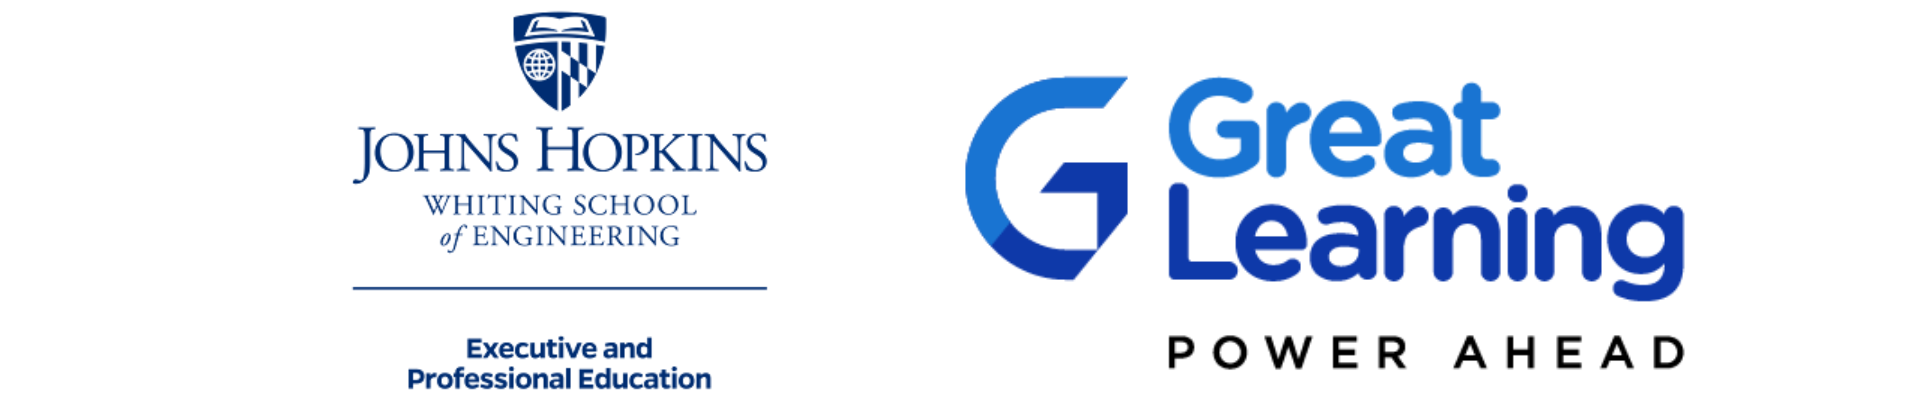

<div style='background: linear-gradient(135deg, #0d2b45 0%, #1f6f78 100%); padding: 32px; border-radius: 14px; color: white;'>
  <h1 style='margin: 0; font-size: 2.3em;'><b>🏦 Senior Mortgage Underwriting System</b></h1>
  <h2 style='margin: 12px 0 0 0; font-weight: 300;'>Multi-Agent System · Agent-to-Agent (A2A) · Model Context Protocol (MCP) · RAG · Human-in-the-Loop · DeepEval</h2>
  <p style='margin: 18px 0 0 0; font-size: 1.05em;'>Build a production-style underwriting workflow where specialist agents analyse a loan file, a Critic peer-reviews their work over A2A, a Decision Agent issues a verdict grounded in policy, and a senior underwriter signs off on the borderline cases - with every run scored by DeepEval.</p>
</div>

---

## 🏢 Business Problem - Consistent, Auditable Loan Decisions

Mortgage underwriting is slow, manual, and inconsistent. A single application requires an underwriter to reconcile credit history, income stability, asset sourcing and property condition against a long policy manual - and two underwriters reading the same file can reach different conclusions. The work is repetitive enough to automate, yet high-stakes enough that automation cannot be careless.

A system that decides loans carries real risk: an approval that should have been declined exposes the lender to default; a decision that leans on a protected characteristic is a Fair Lending violation; a decision no one can explain fails an audit. The goal here is **speed with a paper trail** - compress the manual work into a single run, while grounding every judgement in the written policy and keeping a human on the file wherever discretion is required.

## 🏗️ Solution & Approach

The system is assembled from six layers, each mapped to a specific protocol or technology:

| Layer | Technology | Role |
|---|---|---|
| **Tool infrastructure** | FastMCP server | Exposes the underwriting calculators and policy retrieval so agents never compute figures themselves |
| **Orchestration** | LangGraph (supervisor + specialists) | An LLM-planner Supervisor routes four specialists, drives a rework loop, and releases to the Decision Agent |
| **Inter-agent review** | A2A | The Critic is exposed as a standalone Agent-to-Agent service; the Supervisor calls it as a client |
| **Policy grounding** | RAG (Chroma + section-aware chunking) | Specialists cite the policy manual by section number instead of reasoning from memory |
| **Human oversight** | LangGraph `interrupt()` / `Command` | A conditional approval pauses the graph for a senior underwriter's sign-off |
| **Evaluation** | DeepEval | Six agentic metrics score the trace of every run and end in a single PASS/FAIL |

## 🎯 **Learning Objectives**

By completing this notebook, you will be able to:

✅ **Design a multi-agent system** - split underwriting across four specialist agents coordinated by an LLM-planner Supervisor, so each agent reasons over one policy area instead of one prompt carrying everything.

✅ **Serve tools over MCP** - write a `FastMCP` server exposing the underwriting calculators and RAG policy retrieval, and let each specialist select its tools dynamically with `bind_tools`.

✅ **Ground decisions in policy with RAG** - chunk the policy manual on its numbered headings so retrieved text can be cited as "policy 1.2" rather than appearing as unattributed prose.

✅ **Connect agents with A2A** - expose the Critic as an Agent-to-Agent service with its own Agent Card and skill, and call it from the Supervisor over the protocol.

✅ **Protect data and detect bias** - sanitize PII before the graph ever sees the file, and flag biased or protected-characteristic language in agent output.

✅ **Build native human-in-the-loop review** - pause the workflow with LangGraph's `interrupt()` and resume it with a human decision via `Command(resume=...)`, recording any override with a justification.

✅ **Evaluate with DeepEval** - score the run with six agentic metrics: Task Completion, Tool Correctness, Argument Correctness, Step Efficiency, Plan Quality and Plan Adherence.

---


## **Marking Scheme (Total: 20 Marks)**

<div style='background-color: #fff3e0; padding: 20px; border-radius: 10px; border: 2px solid #ff9800;'>

## <font color="RED">**Part 1: Core Components & MCP Tool Integration (6 marks)**</font>
<font color="magenta">

- PII sanitization system (1 mark)
- Bias detection mechanism (1 mark)
- RAG policy retrieval (2 marks)
- MCP tool server & client integration (2 marks)
</font>

## <font color="RED">**Part 2: Specialist Agents, A2A & HITL (11 marks)**</font>
<font color="magenta">

- Credit Analyst Agent Implementation (1 mark)
- Income Analyst Agent Implementation (1 mark)
- Asset Analyst Agent Implementation (1 mark)
- Collateral Analyst Agent Implementation (1 mark)
- Critic Agent Implementation (1 mark)
- Decision Agent Implementation (1 mark)
- A2A critic service integration - Critic Agent exposed as A2A service, Supervisor as A2A client (2 marks)
- Supervisor planning prompt (1 mark)
- Human-in-the-loop review node - interrupt()/resume logic (1 mark)
- Workflow graph assembly - nodes, edges, conditional routing (1 mark)
</font>

## <font color="RED">**Part 3: Testing & DeepEval Evaluation (2 marks)**</font>
<font color="magenta">

- DeepEval evaluation - custom agentic metric suite & judge model (2 marks)
</font>

## <font color="RED">**Part 4: Summary and Future Scope (1 mark)**</font>
<font color="magenta">

- Summary, Observations & Future Scope (1 mark)
</font>
</div>


---

## 📑 **Table of Contents**

0. [Important Points To Note](#section0)
1. [Introduction & Business Problem](#section1)
2. [System Architecture Overview](#section2)
3. [Environment Setup](#section3)
4. [Data Models & State Management](#section4)
5. [Building Core Components](#section5) - incl. Part E: MCP Tool Server
6. [Implementing Specialist Agents](#section6) - incl. Part F: A2A Critic Service
7. [Complete Workflow Integration](#section7) - incl. Native Human-in-the-Loop
8. [Testing & Evaluation](#section8) - incl. DeepEval
9. [Summary & Future Scope](#section9)

---
<a name='section0'></a>
## 0️⃣ <font color="red"> **# Important Points To Note** </font>

1. This project builds on concepts from previous weeks - refer back to the notebooks where **HITL, DeepEval, MCP, A2A and MAS** were covered if you need a refresher on how to approach any of these components here.
2. For LLM please use **`"gpt-4o-mini"`** model.
3. For project submission, please provide the project in **HTML format.**  Refer to the **"Guidelines: Converting IPYNB to HTML Files.pdf"** for instructions.
4. Ensure all **outputs are clearly visible,** and enclose prompts in triple quotes **`"""`** so they remain fully visible when the notebook is converted from IPYNB to HTML.

---


<a name='section1'></a>
## 1️⃣ **Introduction & Business Problem**

### 🏢 **The Challenge**

Traditional mortgage underwriting is:
- ⏱️ **Time-consuming** - Manual review takes 3-5 days per application
- 📄 **Document-heavy** - Requires analysis of credit reports, pay stubs, bank statements, appraisals
- 🎯 **Inconsistent** - Different underwriters may reach different conclusions
- 💰 **Expensive** - Senior underwriters cost $70-100K+ annually

### 💡 **The Solution**

An **Agentic AI System** that automates the underwriting workflow using:
- Multiple specialized AI agents (Credit, Income, Asset, Collateral analysts)
- Coordinated workflow orchestration
- Policy-based decision making with RAG
- Tools served over **MCP** (the four specialist agents) and the Critic Agent exposed over **A2A**
- Compliance safeguards (PII protection, bias detection)
- Human-in-the-loop for high-risk cases (native pause / resume)
- Automated quality evaluation with **DeepEval**

### 🎯 **Key Features**

✨ Reduces processing time from **days to hours**

✨ Maintains **consistent** decision quality

✨ Provides **audit trail** with reasoning chains

✨ Ensures **regulatory compliance** (Fair Lending Act)

✨ Scales to handle **thousands of applications** simultaneously

---

<a name='section2'></a>
## 2️⃣ **System Architecture Overview**

### 🏗️ **Multi-Agent Architecture**

Our system uses a **hierarchical multi-agent pattern** with three layers:

### 🤖 **Cast of Agents**

Seven LLM roles make up the system - four specialists, a Supervisor that plans and routes, a Critic that peer-reviews, and a Decision Agent that issues the verdict. Each has one job and reads only what it needs.

| Role | Where | Job |
|---|---|---|
| **Supervisor (LLM planner)** | `supervisor_node` | Emits an ordered plan + rationale on the first pass, routes to each specialist, drives the rework loop, and releases to the Decision Agent (enforces `MAX_REVISIONS = 3`) |
| **Credit Analyst** | `credit_analyst_node` | Reviews credit history and derogatory items; cites the credit policy |
| **Income Analyst** | `income_analyst_node` | Verifies employment stability and computes the DTI ratio from tool output |
| **Asset Analyst** | `asset_analyst_node` | Confirms funds to close, checks reserve adequacy, and reviews large deposits |
| **Collateral Analyst** | `collateral_analyst_node` | Assesses property value, LTV and condition against the collateral policy |
| **Critic (A2A service)** | `critic-analyst` service | Peer-reviews the four analyses for inconsistency and policy violations; the only agent exposed over A2A |
| **Decision Agent** | `decision_agent_node` | Synthesises the four analyses and the Critic verdict into a risk score, a decision, and an audit-ready credit memo |

> 💡 **Single-model, deterministic design:** every role uses the same model at `temperature=0`. One model keeps cost predictable and the run reproducible - the same model that writes an analysis also reviews it. In production, the Critic and the DeepEval judge would be upgraded to a stronger, independent model to remove self-preference bias.

### 🔌 **Protocol Layers**

| Layer | Technology | Role in this system |
|-------|-----------|---------------------|
| **Orchestration** | LangGraph | Supervisor (LLM planner) routing, shared state, checkpointing, rework loop |
| **Agent-to-Agent** | A2A | The Supervisor's critic node calls the Critic Agent service (one Agent Card, skill: `critic`) |
| **Tools** | MCP | The four specialist agents call their calculators and the RAG policy retrieval on one shared MCP tool server |
| **Human Oversight** | LangGraph `interrupt()` / `Command` | A CONDITIONAL_APPROVAL pauses for a senior underwriter's decision |
| **Evaluation** | DeepEval | Six agentic metrics: Task Completion, Tool Correctness, Argument Correctness, Step Efficiency, Plan Quality and Plan Adherence |

```
initialize ──▶ Supervisor (LLM planner)
                   │  ▲                              ┌───────────────────────┐
     plan: run/rerun│  │ return to supervisor        │   MCP Tool Server     │
                   ▼  │                              │ 7 calculators + RAG   │
        Specialist Agents (credit, income,  ──tools─▶└────────────────────────┘
        asset, collateral) — all see every tool, pick their own (bind_tools)
                   │  ▲
  all analyses done│  │ verdict + rework_target (rework loop)
                   ▼  │          ┌──────────────────────────────┐
                Critic node ◀──A2A──▶ critic-analyst service (9105)
                   │                 Agent Card | skill: critic
   (Supervisor releases to Decision when the Critic passes, or after MAX_REVISIONS)
                   ▼
              Decision Agent
                   ├──▶ (CONDITIONAL_APPROVAL only) ──▶ Human Review ──▶ END
                   └──▶ (APPROVED / DENIED) ────────────────────────▶ END
```

The **four specialist agents** reach their tools through the MCP server, and the LLM chooses which
tools to call from the full MCP tool set (`bind_tools`). The **Critic** is the single A2A service: the
Supervisor's critic node is the client, and the Critic judges the four grounded analyses rather than
calling MCP itself. The **Decision Agent** likewise reasons from the analyses and the Critic verdict.
Human review is reached **only for a CONDITIONAL_APPROVAL**.


---
### Logical Flow

The diagram below is drawn in plain text so it stays in step with the code. It shows what the
compiled LangGraph diagram cannot: PII sanitization happening **before** the graph is invoked,
that the **Critic** is the one agent reached over **A2A**, and that the **four specialist agents
only** reach their tools over **MCP** (the Critic and Decision agents do not call MCP).

### 🗺️ **Logical Flow & Architecture (at a glance)**

The diagram below is the logical flow of the whole underwriting workflow. It mirrors the compiled LangGraph graph rendered later in Part 7. The Critic always returns its verdict to the Supervisor, which then either reworks a specialist or releases the file to the Decision Agent.

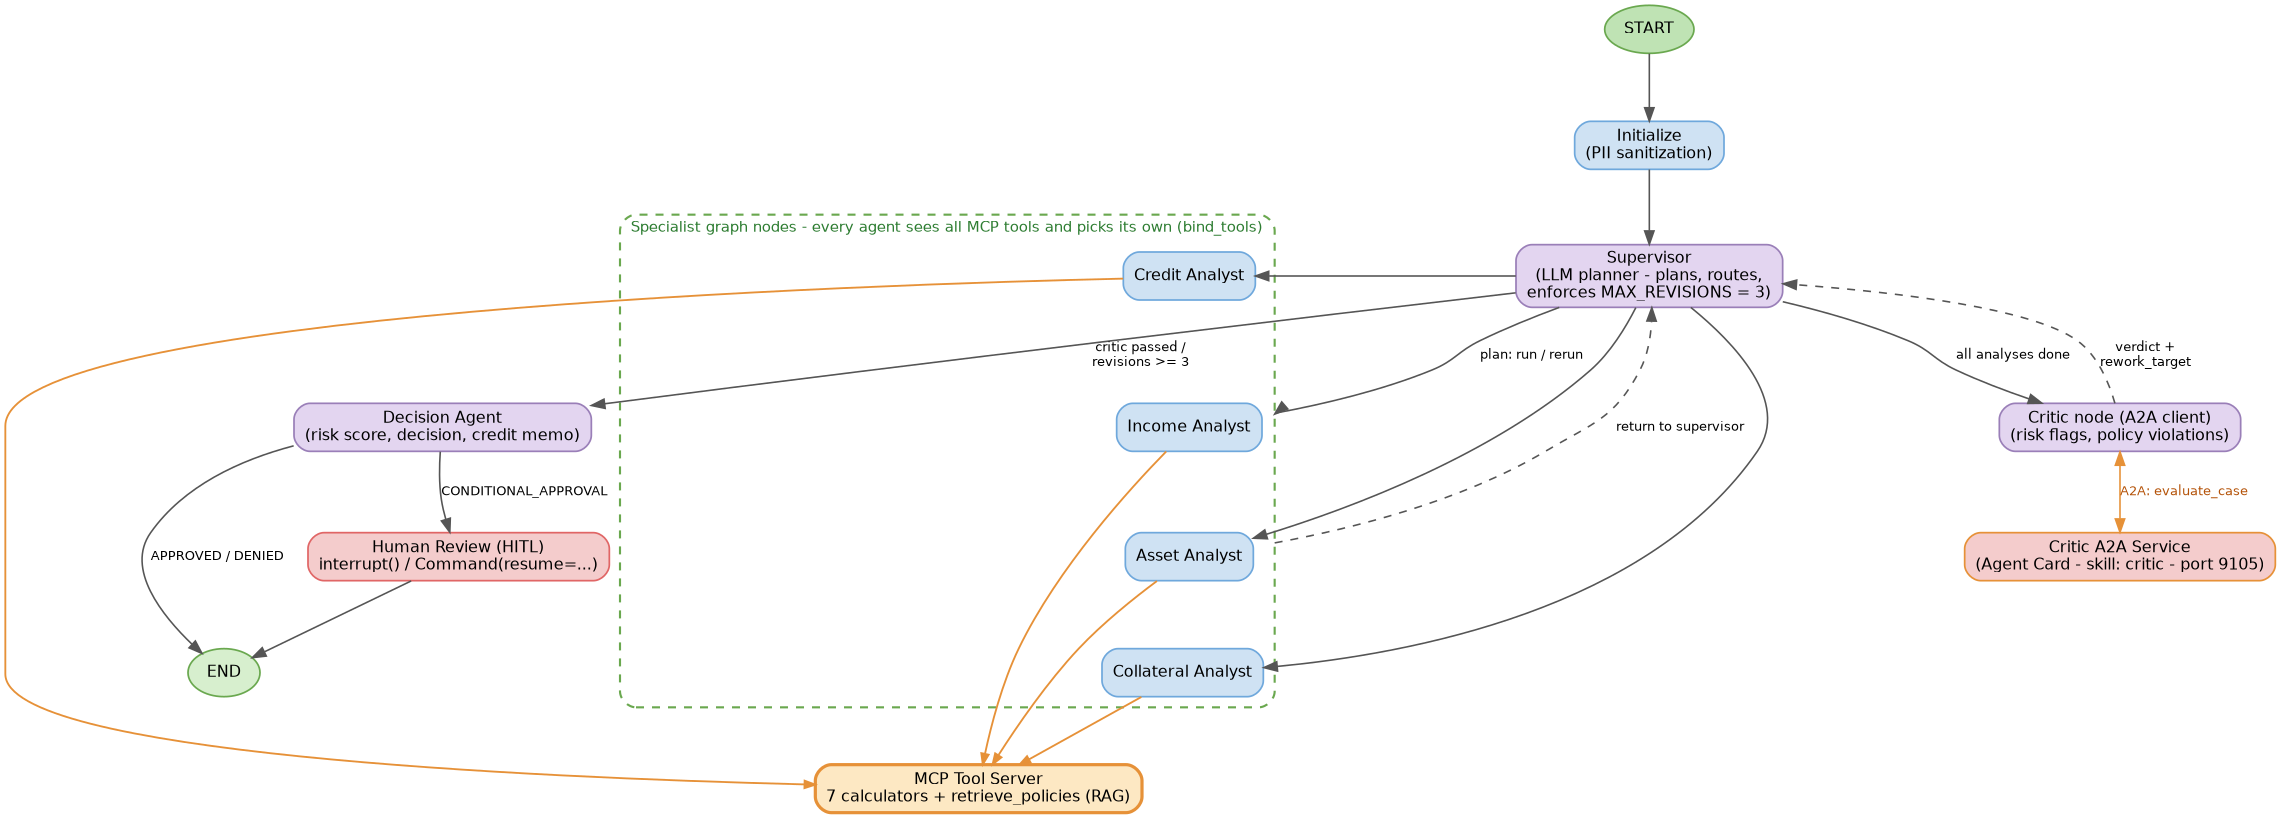

**Protocol boundaries**

- 🟦 **LangGraph** - shared state, conditional routing, checkpointing, and the Critic → Supervisor rework loop (`MAX_REVISIONS = 3`).
- 🟩 **MCP** - one shared tool server, reached by the **four specialist agents only**; each agent sees all tools and picks its own via `bind_tools`.
- 🟥 **A2A** - one service, the **Critic** (`critic-analyst`, port 9105); the Supervisor's `critic` node is the client.
- 🟪 **HITL** - `interrupt()` / `Command(resume=…)`, reached **only for a CONDITIONAL_APPROVAL**; APPROVED and DENIED decisions complete automatically.

---

<a name='section3'></a>
## 3️⃣ **Environment Setup**

<div style='background-color: #e8f5e9; padding: 15px; border-left: 5px solid #4caf50; border-radius: 5px;'>

**What you'll do:**
- Install required packages
- Set up API credentials
- Understand the technology stack

</div>

### 📦 **Technology Stack**

| Technology | Purpose |
|-----------|---------|
| **LangGraph** | Agent orchestration, state management & HITL interrupt/resume |
| **LangChain** | LLM integration & tool management |
| **OpenAI - GPT-4o-mini** | Language model for reasoning (also used as the DeepEval judge) |
| **ChromaDB** | Vector store for policy retrieval |
| **MCP (FastMCP + langchain-mcp-adapters)** | Tool server and client for calculators and policy retrieval |
| **A2A SDK** | Agent-to-Agent service exposing the Critic Agent (the Supervisor is the client) |
| **DeepEval** | Agentic evaluation with six metrics: Task Completion, Tool Correctness, Argument Correctness, Step Efficiency, Plan Quality and Plan Adherence |
| **Python** | Programming language |

### 🔧 **Installation Instructions**

Run the cell below to install all required packages. This may take 2-3 minutes.

In [ ]:
# Install Dependencies
# This will install all required packages for the mortgage underwriting system

%pip install -q \
  langgraph==1.1.9 \
  langchain==1.2.15 \
  langchain-openai==1.1.7 \
  langchain-community==0.4.1 \
  langchain-text-splitters==1.1.0 \
  chromadb==1.5.9 \
  pypdf==6.6.0 \
  "mcp[cli]==1.30.0" \
  langchain-mcp-adapters==0.3.0 \
  nest_asyncio==1.6.0 \
  a2a-sdk==1.1.2 \
  deepeval==4.2.2

print("✅ Packages installed.")
print("\n⚠️ IMPORTANT: this install replaces some packages Colab has already loaded.")
print("   Go to Runtime → Restart session, then run the notebook from the next cell onwards.")

### 📌 **Version Notes**

Versions are pinned on purpose - the MCP, A2A and DeepEval APIs change quickly between releases. Things to know for these versions:

- `langchain-mcp-adapters==0.3.0` returns tool results as MCP **content blocks** (for example `[{'type': 'text', 'text': '...'}]`), not a plain string. The `mcp_text()` helper in Part E converts them to text.
- `mcp==1.30.0`: the `FastMCP` server takes `host` and `port` in its constructor, and `mcp_server.tool()` reads a plain function's type hints and docstring to build the tool schema.
- `a2a-sdk==1.1.2` uses protobuf-based types, for example `part.HasField("text")` and `TaskState.TASK_STATE_COMPLETED`. `TaskUpdater` provides the full task lifecycle: `submit()`, `start_work()`, `complete()`, `failed()` and `cancel()`.
- `deepeval==4.2.2`: the six agentic metrics work on a hand-built `LLMTestCase` with an explicit `_trace_dict`. A custom judge model should accept DeepEval's `schema=` argument (see Section 8).
- `langgraph==1.1.9` provides `interrupt()` / `Command(resume=...)`, emits an `__interrupt__` event while streaming, and exposes pending interrupts on `graph.get_state(config).interrupts`.
- `nest_asyncio==1.6.0` is applied before starting the background MCP and A2A event loops for Colab/Jupyter compatibility.
- A deprecation warning for the `langchain_community` Chroma class may appear; it is safe to ignore.
- The install cell replaces packages Colab has already imported, so **restart the runtime once after installing**, then run from the API-configuration cell onwards.

### 🔑 **API Configuration**

Load your GreatLearning API credentials using **Colab Secrets** (`userdata`). Your secrets should contain:
- `API_KEY` - your GreatLearning API key
- `OPENAI_API_BASE` - the GreatLearning OpenAI proxy endpoint

Set both as environment variables (`OPENAI_API_KEY` and `OPENAI_API_BASE`) so that downstream LangChain calls pick them up automatically.


In [ ]:
# Configure GreatLearning API Keys
# Using GreatLearning's OpenAI proxy service

import os
from google.colab import userdata

# Load secrets from Colab
"Write your code"

print("✅ GreatLearning API configured via Colab Secrets!")
print("Using API Base:", os.environ["OPENAI_API_BASE"])


### 📚 **Import Required Libraries**

Now let's import all the libraries we'll need for building our multi-agent system.

In [ ]:
# Import Core Libraries

import copy
import json
import logging
import operator
import os
import re
import asyncio
import nest_asyncio
import socket
import threading
import time
import traceback
import uuid
from typing import Annotated, TypedDict, List, Dict, Any, Optional, Literal
from datetime import datetime
from pydantic import BaseModel, Field

# Colab/Jupyter compatibility for background asyncio services.
nest_asyncio.apply()

# LangChain & LangGraph
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command          # Native HITL: pause / resume
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage

# Vector Store for RAG
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

# Local servers (host the MCP tool server and the Critic A2A service)
import httpx
import uvicorn
from starlette.applications import Starlette

# MCP - Model Context Protocol (tool server + client)
from mcp.server.fastmcp import FastMCP
from langchain_mcp_adapters.client import MultiServerMCPClient

# A2A - Agent-to-Agent protocol (agent service + client)
from a2a import types as a2a_types
from a2a.client import A2ACardResolver, ClientFactory, ClientConfig
from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import create_agent_card_routes, create_jsonrpc_routes
from a2a.server.tasks import InMemoryTaskStore, TaskUpdater

# Keep notebook output clean: silence warnings and quiet the noisy service loggers.
import warnings
warnings.filterwarnings("ignore")                 # hide deprecation / runtime warnings
logging.captureWarnings(True)

# MCP / HTTP / A2A libraries log every request at INFO level - raise them to ERROR so only
# genuine problems surface in the output.
for _logger_name in ["mcp", "httpx", "httpcore", "uvicorn", "uvicorn.access", "uvicorn.error",
                     "sse_starlette", "a2a", "asyncio", "langchain", "chromadb", "deepeval"]:
    logging.getLogger(_logger_name).setLevel(logging.ERROR)

print("✅ All libraries imported successfully!")
print("\n🎉 Environment setup complete! You're ready to build the system.")

---

<a name='section4'></a>
## 4️⃣ **Data Models & State Management**

### 🗂️ **Understanding State Management**

In a multi-agent system, **state** is the shared memory that all agents can read and write to. Think of it as a shared whiteboard where:
- Each agent writes their analysis results
- The supervisor tracks workflow progress
- The decision agent reads all findings to make final decision

### 💡 **Key Concepts**

**TypedDict**: Python's way of defining structured data with type hints

**State Graph**: LangGraph's state machine that manages workflow transitions

### 🏗️ **Define the State Schema**

Below we define the structure that will hold all data as it flows through our system.

In [ ]:
# Define Application State Schema

class UnderwritingState(TypedDict):
    """The complete state of a loan application as it moves through the system."""

    # Application Information
    # Only the sanitized record is carried. The raw application never enters the state,
    # so the checkpointer cannot persist a name, SSN, phone, email or address.
    case_id: str
    sanitized_data: Dict[str, Any]

    # Agent Analysis Results
    credit_analysis: Optional[str]
    income_analysis: Optional[str]
    asset_analysis: Optional[str]
    collateral_analysis: Optional[str]

    # Supervisor Planner
    supervisor_plan: Optional[str]                        # structured plan text emitted on the first pass
    plan_history: Annotated[List[str], operator.add]     # every plan / rework / routing decision
    revision_count: int                                  # reworks done so far; capped at MAX_REVISIONS
    rework_target: Optional[str]                          # specialist the Critic asked to redo
    next_agent: Optional[str]                             # routing signal set by supervisor_node

    # DeepEval Trace Capture
    tool_trace: Annotated[List[Dict[str, Any]], operator.add]   # per-agent MCP tool calls

    # Coordination & Decision
    critic_review: Optional[str]
    critic_verdict: Optional[str]
    decision_memo: Optional[str]
    final_decision: Optional[str]  # APPROVED, DENIED, CONDITIONAL_APPROVAL
    risk_score: Optional[int]      # 0-100

    # Workflow Control
    human_review_required: bool
    review_reasons: List[str]      # Why review was triggered - set once by the Decision Agent
    human_review_completed: bool
    human_notes: Optional[str]
    ai_decision: Optional[str]           # AI recommendation, preserved before human review
    human_decision: Optional[str]        # Reviewer's decision, submitted via Command(resume=...)
    human_override: bool                 # True when the reviewer departed from the AI recommendation
    override_justification: Optional[str]  # Required whenever human_override is True

    # Compliance
    policy_violations: List[str]
    risk_flags: List[str]                            # Key risks identified by the Critic Agent
    bias_flags: Annotated[List[str], operator.add]   # Reducer: every node appends, never overwrites

    # Audit Trail
    reasoning_chain: Annotated[List[str], operator.add]   # Reducer: each node appends its own step
    timestamp: str


def apply_delta(state: Dict[str, Any], delta: Dict[str, Any]) -> Dict[str, Any]:
    """Merge a node's delta into a plain dict the same way the graph's reducers would.

    The graph applies the Annotated[..., operator.add] reducers automatically.
    The single-agent demo cells call the nodes directly, so they use this helper.
    """
    merged = {**state, **delta}
    for key in ("bias_flags", "reasoning_chain", "plan_history", "tool_trace"):
        if key in delta:
            merged[key] = list(state.get(key, [])) + list(delta[key])
    return merged


print("✅ State schema defined!")
print("\n📋 The state will track:")
print("  - Application data (sanitized only - the raw record never enters the graph)")
print("  - The Supervisor plan, rework target and revision count (LLM planner + rework loop)")
print("  - All agent analyses and the per-agent MCP tool_trace (used by DeepEval)")
print("  - Decision and risk assessment")
print("  - Compliance flags")
print("  - Complete audit trail")
print("\n🔁 bias_flags, reasoning_chain, plan_history and tool_trace use operator.add reducers,")
print("   so nodes return only their own additions and the graph merges them.")


---

---
## 📝 <font color="RED">**Part 1: Core Agent Implementation & MCP Tool Integration (9 marks)**</font>

**What you'll build:**
<font color="magenta">
- Utility tools for calculations (2 marks)
- PII sanitization system (1 mark)
- Bias detection mechanism (1 mark)
- RAG policy retrieval (2 marks)
- MCP tool server & client integration (2 marks)
- Test data preparation (1 mark)
</font>
---

<a name='section5'></a>
## 5️⃣ **Building Core Components**

### 🛠️ **Part A: Utility Tools**

These tools perform the calculations the agents need. They are **plain Python functions** with explicit type hints and docstrings - Part E registers them on the MCP server, which turns each signature into the tool's JSON schema. Defining them once, as ordinary functions, means there is a single definition of every tool rather than one for LangChain and another for MCP.

**Why tools matter:**
- LLMs can't do precise math reliably
- Tools ensure accurate calculations
- Results are deterministic and auditable
- Typed arguments (`List[Dict[str, Any]]`, `Dict[str, float]`) give MCP clients a schema they can actually fill

Alongside the tools, the same cell defines **`case_metrics()`** - one function that derives every
headline figure (qualifying income, back-end DTI, LTV, cash to close, post-closing reserves) from
an application record. The agents, the run cells, the final reports and the evaluation all read
their numbers from it, so no two places in the notebook can print a different DTI for the same case.

In [ ]:
# Utility Tools for Underwriting Calculations
# Plain Python functions with explicit type hints and docstrings.
# Part E registers these directly on the MCP server, which turns the type hints
# into the tools' JSON schemas - so the signature below IS the tool contract.

def calculate_dti_ratio(monthly_debt: float, monthly_income: float) -> str:
    """Calculate the back-end Debt-to-Income ratio (policy 2.6).

    Args:
        monthly_debt: Existing monthly debt obligations PLUS the proposed housing payment
        monthly_income: Qualifying monthly gross income

    Returns:
        Formatted DTI ratio result
    """
    if monthly_income <= 0:
        return "Error: Monthly income must be greater than 0"

    dti = (monthly_debt / monthly_income) * 100
    status = "Acceptable" if dti <= 43 else "High" if dti <= 50 else "Excessive"

    return (f"DTI Ratio: {round(dti, 2)}% ({status}) - "
            f"Debt: ${monthly_debt:,.2f}, Income: ${monthly_income:,.2f}")


def calculate_ltv_ratio(loan_amount: float, property_value: float) -> str:
    """Calculate Loan-to-Value ratio.

    Args:
        loan_amount: The loan amount requested
        property_value: Value the LTV is measured against (the LOWER of purchase
            price and appraised value, which is the basis this notebook uses)

    Returns:
        Formatted LTV ratio result
    """
    if property_value <= 0:
        return "Error: Property value must be greater than 0"

    ltv = (loan_amount / property_value) * 100
    status = ("Excellent" if ltv <= 80 else "Good" if ltv <= 90
              else "High" if ltv <= 97 else "Excessive")

    return (f"LTV Ratio: {round(ltv, 2)}% ({status}) - "
            f"Loan: ${loan_amount:,.2f}, Value: ${property_value:,.2f}")


def calculate_reserves(liquid_assets: float, monthly_payment: float,
                       required_months: int = 2, cash_to_close: float = 0.0) -> str:
    """Calculate POST-CLOSING reserve coverage in months of PITI (policy 3.1).

    Policy 3.1 defines reserves as the liquid assets remaining *after* closing, so the
    cash the borrower must bring to the table (down payment + closing costs) is deducted
    before the coverage is counted. A borrower who cannot fund closing has no reserves at
    all, however large the balance looked beforehand.

    Only checking and savings are counted. Retirement balances are excluded here: policy
    3.5 allows them at 60-70% of value, and this notebook takes the conservative view.

    Args:
        liquid_assets: Verified liquid assets before closing (checking + savings)
        monthly_payment: Monthly PITI payment
        required_months: Months of PITI this risk profile must hold (policy 3.1)
        cash_to_close: Down payment plus closing costs, deducted before counting reserves

    Returns:
        Formatted post-closing reserves analysis
    """
    if monthly_payment <= 0:
        return "Error: Monthly payment must be greater than 0"

    remaining = liquid_assets - cash_to_close
    required_amount = monthly_payment * required_months

    if remaining < 0:
        return (f"Reserves: INSUFFICIENT - borrower cannot fund closing. Liquid assets of "
                f"${liquid_assets:,.2f} fall ${abs(remaining):,.2f} short of the "
                f"${cash_to_close:,.2f} cash required to close, leaving no reserves.")

    months_coverage = remaining / monthly_payment
    status = "Adequate" if months_coverage >= required_months else "Insufficient"
    result = (f"Reserves: {round(months_coverage, 1)} months post-closing coverage ({status}) - "
              f"Liquid: ${liquid_assets:,.2f}, Cash to close: ${cash_to_close:,.2f}, "
              f"Remaining: ${remaining:,.2f}, Required: ${required_amount:,.2f} "
              f"({required_months} months PITI)")
    shortfall = required_amount - remaining
    if shortfall > 0:
        result += f", Shortfall: ${shortfall:,.2f}"
    return result


def calculate_housing_expense_ratio(monthly_payment: float, monthly_income: float) -> str:
    """Calculate housing expense ratio (front-end ratio, policy 2.6).

    Args:
        monthly_payment: Monthly PITI payment
        monthly_income: Qualifying monthly gross income

    Returns:
        Formatted housing expense ratio
    """
    if monthly_income <= 0:
        return "Error: Monthly income must be greater than 0"

    ratio = (monthly_payment / monthly_income) * 100
    status = "Acceptable" if ratio <= 28 else "Elevated" if ratio <= 35 else "High"

    return (f"Housing Ratio: {round(ratio, 2)}% ({status}) - "
            f"Payment: ${monthly_payment:,.2f}, Income: ${monthly_income:,.2f}")


def check_credit_score_policy(credit_score: int) -> str:
    """Check if a credit score meets policy requirements.

    Args:
        credit_score: Borrower's credit score

    Returns:
        Policy compliance result with the applicable tier
    """
    if credit_score >= 740:
        tier, rate_adjustment = "Excellent", "Best rates available"
    elif credit_score >= 700:
        tier, rate_adjustment = "Very Good", "Favorable rates"
    elif credit_score >= 660:
        tier, rate_adjustment = "Good", "Standard rates"
    elif credit_score >= 620:
        tier, rate_adjustment = "Fair", "Higher rates, may require compensating factors"
    else:
        tier, rate_adjustment = "Below Minimum", "Does not meet conventional loan requirements"

    return f"Credit Score: {credit_score} - Tier: {tier} - {rate_adjustment}"


def check_large_deposits(deposits: List[Dict[str, Any]], monthly_income: float) -> str:
    """Identify deposits requiring sourcing documentation (policy 3.3).

    Policy 3.3 sets the threshold at $1,000 OR 25% of monthly income, whichever is LESS,
    and applies it to deposits *exceeding* that amount. It also accepts payroll deposits
    that match the paystubs, so each qualifying deposit is placed in one of three groups
    using its description rather than all being reported as unsourced.

    Args:
        deposits: Recent deposits, e.g.
            [{"amount": 22000.0, "date": "2024-12-15", "description": "Annual bonus"}]
        monthly_income: Qualifying monthly gross income, for the 25% half of the threshold

    Returns:
        Deposits grouped into payroll, explained and unsourced
    """
    threshold = min(1000.0, monthly_income * 0.25)
    payroll_terms = ("salary", "payroll", "wage", "paycheck", "direct deposit")
    explained_terms = ("bonus", "commission", "tax refund", "transfer", "sale of",
                       "gift", "client payment", "dividend")

    payroll: List[str] = []
    explained: List[str] = []
    unsourced: List[str] = []

    for dep in deposits:
        amount = dep.get("amount", 0)
        if amount <= threshold:                       # policy says "exceeding", so > not >=
            continue
        description = str(dep.get("description", "")).strip()
        entry = (f"${amount:,.2f} on {dep.get('date', 'Unknown')} - "
                 f"{description or 'no description provided'}")
        text = description.lower()
        if any(term in text for term in payroll_terms):
            payroll.append(entry)
        elif any(term in text for term in explained_terms):
            explained.append(entry)
        else:
            unsourced.append(entry)

    total = len(payroll) + len(explained) + len(unsourced)
    if total == 0:
        return (f"No deposits exceed the ${threshold:,.2f} threshold (policy 3.3) - "
                "no sourcing documentation required.")

    lines = [f"Found {total} deposit(s) above the ${threshold:,.2f} threshold (policy 3.3); "
             f"{len(unsourced)} still unsourced:"]
    for label, group, note in (
        ("PAYROLL", payroll, "acceptable - verify against paystubs and the employment verification"),
        ("EXPLAINED", explained, "explanation on file - obtain the supporting evidence"),
        ("UNSOURCED", unsourced, "SOURCING DOCUMENTATION REQUIRED before closing"),
    ):
        if group:
            lines.append(f"  {label} ({len(group)}) - {note}:")
            lines.extend(f"    - {item}" for item in group)
    return "\n".join(lines)


def calculate_total_debt_obligations(debts: Dict[str, float], proposed_payment: float) -> str:
    """Calculate total monthly debt obligations including the proposed loan payment.

    Args:
        debts: Monthly payments by debt name, e.g. {"car_loan": 1200.0}
        proposed_payment: Proposed monthly loan payment

    Returns:
        Total debt calculation with a per-debt breakdown
    """
    current_debt = sum(debts.values())
    breakdown = "\n".join(f"  - {k}: ${v:,.2f}" for k, v in debts.items())

    return (f"Total Monthly Obligations: ${current_debt + proposed_payment:,.2f}\n"
            f"Current Debt: ${current_debt:,.2f}\n{breakdown}\n"
            f"Proposed Payment: ${proposed_payment:,.2f}")


# The 7 calculators, in one list. Part E registers exactly this list on the MCP server.
calculator_tools = [
    calculate_dti_ratio,
    calculate_ltv_ratio,
    calculate_reserves,
    calculate_housing_expense_ratio,
    check_credit_score_policy,
    check_large_deposits,
    calculate_total_debt_obligations,
]

# Some records carry a pre-computed summary key alongside the individual debts.
# Summing it with the components would double-count, so it is excluded here.
DEBT_SUMMARY_KEYS = {"total_monthly_debt", "total_debt", "monthly_debt_total"}


def monthly_debt_payments(debts: Dict[str, float]) -> Dict[str, float]:
    """Return only the individual monthly debt payments (no pre-computed totals)."""
    return {k: v for k, v in debts.items() if k not in DEBT_SUMMARY_KEYS}


print("✅ Calculator tools created!")
for fn in calculator_tools:
    print(f"  • {fn.__name__}")


# Report labels, derived from the same bands the calculators above use,
# so a printed verdict can never contradict the number next to it.
def rate_dti(dti_pct: float) -> str:
    return "Within limits" if dti_pct <= 43 else "High" if dti_pct <= 50 else "Excessive"


def rate_ltv(ltv_pct: float) -> str:
    return ("Excellent" if ltv_pct <= 80 else "Good" if ltv_pct <= 90
            else "High" if ltv_pct <= 97 else "Excessive")


def rate_credit(score: int) -> str:
    return ("Excellent" if score >= 740 else "Very Good" if score >= 700
            else "Good" if score >= 660 else "Fair" if score >= 620 else "Below Minimum (620)")


def rate_down_payment(down_payment: float, purchase_price: float) -> str:
    pct = (down_payment / purchase_price * 100) if purchase_price else 0
    return f"{pct:.1f}% - " + ("Strong" if pct >= 20 else "Standard" if pct >= 10 else "Low")


# ---------------------------------------------------------------------------
# One definition of every headline figure
# ---------------------------------------------------------------------------
# The agents, the detailed run cells, the final reports and the evaluation all read
# their numbers from case_metrics(), so no two places in this notebook can print a
# different DTI, LTV or reserve figure for the same application.

def qualifying_monthly_income(app: Dict[str, Any]) -> Dict[str, Any]:
    """Monthly income that may be used to qualify the borrower (policy 2.4).

    Base employment income always counts. Bonus income counts only when it has a
    two-year history AND the employer has confirmed it is likely to continue; a
    declining trend is taken at the lower (most recent) year rather than averaged.

    Returns:
        {"base", "bonus", "total", "note"} - the note explains the bonus treatment
    """
    employment = app.get("employment", {})
    details = employment.get("income_details", {})
    base = float(employment.get("monthly_income", 0) or 0)
    prior_year = float(details.get("bonus_2023", 0) or 0)
    recent_year = float(details.get("bonus_2024", 0) or 0)

    def result(bonus: float, note: str) -> Dict[str, Any]:
        return {"base": base, "bonus": bonus, "total": base + bonus, "note": note}

    if not details:
        return result(0.0, "No variable income on file - base employment income only.")
    if prior_year <= 0 or recent_year <= 0:
        return result(0.0, "Bonus EXCLUDED (policy 2.4): a two-year history of bonus income "
                           "is required and only one year is documented.")
    if not details.get("bonus_stable"):
        return result(0.0, "Bonus EXCLUDED (policy 2.4): the employer has not confirmed the "
                           "bonus is likely to continue.")

    if recent_year < prior_year:                       # declining trend: use the lower year
        annual, basis = recent_year, "most recent year (declining trend)"
    else:
        annual, basis = (prior_year + recent_year) / 2, "2-year average"
    bonus = annual / 12
    return result(bonus, f"Bonus INCLUDED (policy 2.4): {basis} of ${prior_year:,.0f} and "
                         f"${recent_year:,.0f} = ${bonus:,.2f} per month.")


def required_reserve_months(app: Dict[str, Any], back_end_dti: float) -> Dict[str, Any]:
    """Months of PITI reserves this profile must hold (policy 3.1).

    Policy 3.1 sets 2 months for a conventional primary residence and calls for
    additional reserves on higher-risk profiles, so the requirement is derived from
    the file rather than fixed at 2 for every applicant.
    """
    reasons = []
    if app.get("credit_score", 0) < 660:
        reasons.append("credit score below 660")
    if back_end_dti > 43:
        reasons.append("back-end DTI above 43%")
    if "self" in str(app.get("employment", {}).get("type", "")).lower():
        reasons.append("self-employed income")
    if float(app.get("employment", {}).get("years", 0) or 0) < 2:
        reasons.append("under 2 years in the current position")
    return {"months": 6 if reasons else 2, "reasons": reasons}


def dti_compensating_factors(back_end_dti: float, credit_score: int, reserve_months: float,
                             down_payment_pct: float, required: int = 2) -> str:
    """Apply policy 2.6's compensating-factor allowance for DTI between 43% and 50%.

    Policy 2.6 lists the qualifying factors but does not say how many are needed, so
    this notebook states its own rule - at least `required` of them - rather than
    leaving the judgement to the model.
    """
    if back_end_dti <= 43:
        return "Within the 43% conventional back-end limit (policy 2.6)."
    if back_end_dti > 50:
        return (f"{back_end_dti:.1f}% exceeds the 50% maximum in policy 2.6 - no combination "
                "of compensating factors can bring it inside the limit.")

    present = [name for ok, name in (
        (credit_score >= 720, "excellent credit (720+)"),
        (reserve_months >= 12, "12+ months post-closing reserves"),
        (down_payment_pct >= 25, "25%+ down payment"),
    ) if ok]
    verdict = "ALLOWED" if len(present) >= required else "NOT allowed"
    return (f"{back_end_dti:.1f}% sits in the 43-50% compensating-factor band (policy 2.6): "
            f"{len(present)} of {required} required factor(s) present "
            f"{present or '[none]'} - exception {verdict}.")


def case_metrics(app: Dict[str, Any]) -> Dict[str, Any]:
    """Every headline figure for one application, computed once from the record."""
    employment = app.get("employment", {})
    loan = app.get("loan", {})
    prop = app.get("property", {})
    assets = app.get("assets", {})

    income = qualifying_monthly_income(app)
    qualifying_income = income["total"]

    debts = monthly_debt_payments(app.get("debts", {}))
    existing_debt = sum(debts.values())
    piti = float(loan.get("estimated_payment", loan.get("monthly_piti", 0)) or 0)

    back_end_dti = ((existing_debt + piti) / qualifying_income * 100) if qualifying_income else 0.0
    front_end_ratio = (piti / qualifying_income * 100) if qualifying_income else 0.0

    purchase_price = float(prop.get("purchase_price", 0) or 0)
    appraised_value = float(prop.get("appraised_value", 0) or 0)
    # LTV is measured against the LOWER of purchase price and appraised value - the
    # standard basis when an appraisal comes in below contract. Policy 4.3 caps the result.
    candidates = [v for v in (purchase_price, appraised_value) if v > 0]
    ltv_basis = min(candidates) if candidates else 0.0
    loan_amount = float(loan.get("amount", 0) or 0)
    ltv = (loan_amount / ltv_basis * 100) if ltv_basis else 0.0

    down_payment = float(loan.get("down_payment", 0) or 0)
    closing_costs = float(loan.get("closing_costs", 0) or 0)
    cash_to_close = down_payment + closing_costs
    liquid_assets = float(assets.get("checking", 0) or 0) + float(assets.get("savings", 0) or 0)
    post_closing_liquid = liquid_assets - cash_to_close
    reserve_months = (post_closing_liquid / piti) if piti else 0.0
    reserve_requirement = required_reserve_months(app, back_end_dti)
    down_payment_pct = (down_payment / purchase_price * 100) if purchase_price else 0.0

    return {
        "case_id": app.get("case_id"),
        # Income (policy 2.4 / 2.6)
        "base_income": income["base"],
        "bonus_income": income["bonus"],
        "qualifying_income": qualifying_income,
        "income_note": income["note"],
        "monthly_debts": debts,
        "existing_debt": existing_debt,
        "piti": piti,
        "back_end_dti": back_end_dti,
        "front_end_ratio": front_end_ratio,
        "dti_exception": dti_compensating_factors(back_end_dti, app.get("credit_score", 0),
                                                  reserve_months, down_payment_pct),
        # Collateral (policy 4.2 / 4.3)
        "loan_amount": loan_amount,
        "purchase_price": purchase_price,
        "appraised_value": appraised_value,
        "appraisal_gap": appraised_value - purchase_price,
        "ltv_basis": ltv_basis,
        "ltv": ltv,
        "required_repairs": float(prop.get("required_repairs", 0) or 0),
        # Assets (policy 3.1 / 3.3)
        "down_payment": down_payment,
        "down_payment_pct": down_payment_pct,
        "closing_costs": closing_costs,
        "cash_to_close": cash_to_close,
        "liquid_assets": liquid_assets,
        "post_closing_liquid": post_closing_liquid,
        "reserve_months": reserve_months,
        "required_reserve_months": reserve_requirement["months"],
        "reserve_risk_reasons": reserve_requirement["reasons"],
        "reported_reserve_months": assets.get("reserves_months"),
    }


print("✅ Shared metric helpers created!")
print("  • qualifying_monthly_income  - base income plus bonus only where policy 2.4 allows it")
print("  • required_reserve_months    - 2 months, or 6 for a higher-risk profile (policy 3.1)")
print("  • dti_compensating_factors   - the 43-50% exception test (policy 2.6)")
print("  • case_metrics               - one source of truth for DTI, LTV, reserves and cash to close")


### 🔒 **Part B: PII Sanitization**

**Why PII Sanitization Matters:**
- Protects borrower privacy
- Complies with data protection regulations (GDPR, CCPA)
- Reduces liability if external APIs are compromised

**What gets sanitized:**
- Social Security Numbers → `***-**-XXXX`
- Full names → `[APPLICANT_NAME]`
- Addresses → `[ADDRESS]`
- Phone numbers → `***-***-XXXX`
- Email addresses → `[EMAIL]`

In [ ]:
# PII Sanitization Functions

# Fields replaced wherever they appear, including inside nested objects.
PII_REDACTIONS = {
    "name": "[APPLICANT_NAME]",
    "address": "[ADDRESS]",
    "email": "[EMAIL]",
    "employer": "[EMPLOYER]",
}

# Evaluation-only fields that must never reach an agent or travel over A2A.
EVALUATION_ONLY_KEYS = {"expected_decision"}

# =================================================================
# YOUR TASK: Implement PII redaction  (1 mark)
# =================================================================
def _redact(node: Any) -> Any:
    """Walk the record and redact PII at every level (not just the top level)."""
    # YOUR TASK
    ...
    # ----------


def sanitize_pii(data: Dict[str, Any]) -> Dict[str, Any]:
    """Remove or redact personally identifiable information.

    Args:
        data: Raw application data

    Returns:
        A deep copy, safe for LLM processing and for sending over A2A
    """
    # YOUR TASK
    ...
    # ----------


# Protected characteristics under the Fair Lending Act (ECOA / Fair Housing Act).
# Word-boundary regex patterns avoid false positives such as "age" inside "mortgage".
PROTECTED_PATTERNS = {
    "race": r"\brac(e|ial)\b",
    "color": r"\bcolou?r\b",
    "religion": r"\breligio(n|us)\b",
    "national origin": r"\bnational origin\b",
    "sex": r"\bsex\b",
    "gender": r"\bgender\b",
    "marital status": r"\bmarital\b",
    "age": r"\bage\b",
    "disability": r"\bdisab(led|ility)\b",
    "familial status": r"\bfamilial\b",
}


# Underwriting phrases that contain a protected-characteristic word but are not bias signals:
# credit-file age metrics, and the policy document's own "Social Security/Disability income" wording.
BENIGN_CONTEXTS = [
    r"\b(?:average |)age of (?:the )?(?:oldest |)(?:credit |)(?:tradeline|account|trade line)s?\b",
    r"\boldest (?:credit |)(?:tradeline|account|trade line)\b",
    r"\bcredit (?:file |history |)age\b",
    r"\bsocial security\s*/?\s*disability\b",
    r"\bdisability income\b",
]

GEOGRAPHIC_PATTERN = r"\b(neighbou?rhood|zip ?code|postal code|area demographics)\b"

# =================================================================
# YOUR TASK: Implement bias-signal detection  (1 mark)
# =================================================================
def detect_bias_signals(analysis: str, applicant_data: Dict[str, Any]) -> List[str]:
    """Check any agent-generated text for potential Fair Lending Act violations.

    Args:
        analysis: Agent's analysis, review or memo text
        applicant_data: Applicant information (unused for matching; kept for auditability)

    Returns:
        List of detected bias flags (one flag per characteristic)
    """
    # YOUR TASK
    ...
    # ----------


print("✅ PII sanitization system created!")
print("\n🛡️ Protection features:")
print("  - SSN, phone, name, address, email and employer redacted at every nesting level")
print("  - Deep copy, so the raw application record is never mutated")
print("  - Evaluation-only fields (expected_decision) stripped before any agent sees the data")
print("  - Bias signal detection, applied to every agent's text output")
print("  - Benign underwriting phrases excluded, and each flag carries the matched snippet")


---

### 📚 **Part C: RAG Policy Retrieval**

**What is RAG (Retrieval-Augmented Generation)?**

RAG allows our agents to retrieve relevant bank policies and guidelines dynamically. Instead of having all policies in the prompt (which would exceed token limits), we:
1. Split the policy PDF on its numbered section headings (`1.2`, `3.3`, ...), so every chunk is a whole rule rather than a fixed-size slice, and store it in a vector database (ChromaDB) with its section number as metadata
2. Convert queries to embeddings
3. Find the most relevant policy sections
4. Provide only relevant policies to the agent, labelled with the section they came from

**Benefits:**
- ✅ Handles thousands of pages of policies
- ✅ Always retrieves the most current guidelines
- ✅ Reduces context size for faster processing
- ✅ Easy to update when policies change

In [ ]:
# Policy sections are numbered ("1.2 Bankruptcy Discharge Requirements", "3.3 Large Deposit
# Requirements", ...). Splitting on those headings first means every chunk is a whole policy
# section with its section number attached, so retrieval returns complete rules and the
# grouping below can key on real metadata instead of guessing from the chunk text.
SECTION_SPLIT_PATTERN = r"(?m)^(?=\s*\d\.\d\s+[A-Z])"
SECTION_HEADING_PATTERN = r"^\s*(\d\.\d)\s+(.+)"


def split_policies_by_section(raw_text: str) -> List[Dict[str, str]]:
    """Split the policy text into numbered sections, each with its heading as metadata."""
    sections = []
    for block in re.split(SECTION_SPLIT_PATTERN, raw_text):
        block = block.strip()
        if not block:
            continue
        heading = re.match(SECTION_HEADING_PATTERN, block)
        label = f"{heading.group(1)} {heading.group(2).strip()}" if heading else "PREAMBLE"
        sections.append({"section": label, "text": block})
    return sections


# =================================================================
# YOUR TASK: Create the policy vector store  (1 of 2 RAG marks)
# =================================================================
# Complete create_policy_store() so it builds and returns a Chroma vector store indexed
# over the policy PDF. Steps:
#   1. Load the PDF with PyPDFLoader("underwriting_policies.pdf") and call .load().
#   2. Join every page's .page_content into one string with "\n".join(...).
#   3. Call split_policies_by_section(full_text) (given above) to get whole-section chunks.
#   4. For sections that are still too long, further split each section's text with
#      RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=100).split_text(...).
#      Collect the resulting pieces into policy_chunks, and a matching list of
#      metadatas = [{"section": section["section"]}, ...] (one metadata dict per chunk).
#   5. Create embeddings = OpenAIEmbeddings(base_url=os.environ["OPENAI_API_BASE"]).
#   6. Build vectorstore = Chroma.from_texts(texts=policy_chunks, embedding=embeddings,
#      metadatas=metadatas, collection_name=f"underwriting_policies_{uuid.uuid4().hex[:8]}")
#      - the unique collection name means re-running this cell never appends to an old index.
#   7. Return vectorstore.
#    chunk's metadata always lines up with the chunk itself (same index in both lists).
# =============================================================================

def create_policy_store():
    """Create vector store with underwriting policies (loaded from PDF).

    Returns:
        ChromaDB vector store for policy retrieval
    """
    # YOUR TASK
    ...
    # ----------


# =================================================================
# YOUR TASK: Implement policy retrieval    (1 of 2 RAG marks)
# =================================================================
# Complete retrieve_relevant_policies(query, vectorstore) -> str. Steps:
#   1. docs = vectorstore.similarity_search(query, k=6)
#   2. Group the results by their "section" metadata (doc.metadata.get("section", "OTHER")):
#      build a dict mapping section -> combined text, so if two chunks share a section you
#      append the new text rather than overwriting (and don't duplicate identical text).
#   3. Return everything joined as:
#        "[Policy <section>]\n<text>"   for each section, separated by a blank line.
#      (This exact "[Policy ...]" format is what the direct-test cell below checks for.)
#    is the section label you stored as metadata when you built the store above.
# =============================================================================

def retrieve_relevant_policies(query: str, vectorstore) -> str:
    """Retrieve the most relevant policy text, grouped by its policy section number."""
    # YOUR TASK
    ...
    # ----------


# System initialization
vectorstore = create_policy_store()

print("✅ RAG policy system created!")
print("\n📖 Policy coverage:")
print("  - Credit guidelines")
print("  - Income verification rules")
print("  - Asset requirements")
print("  - Collateral standards")


In [ ]:
# Test the tools directly (before serving them over MCP)
# Each calculator is a plain function and the RAG retriever is a plain function too.
# Here we call them in-process to confirm they work and return sensible results.

print("="*80)
print("🧪 DIRECT TOOL TESTS (in-process)")
print("="*80)

# --- Calculators ---
direct_checks = [
    ("calculate_dti_ratio",              {"monthly_debt": 3800, "monthly_income": 12500}),
    ("calculate_ltv_ratio",             {"loan_amount": 400000, "property_value": 515000}),
    ("calculate_housing_expense_ratio", {"monthly_payment": 3200, "monthly_income": 12500}),
    ("calculate_reserves",              {"liquid_assets": 185000, "monthly_payment": 3200,
                                         "required_months": 2, "cash_to_close": 112000}),
    ("check_credit_score_policy",       {"credit_score": 760}),
    ("calculate_total_debt_obligations",{"debts": {"car_loan": 1200, "student_loan": 800},
                                         "proposed_payment": 3200}),
    ("check_large_deposits",            {"deposits": [{"amount": 22000, "date": "2024-12-15",
                                                       "description": "Annual bonus"}],
                                         "monthly_income": 14166.67}),
]
direct_fns = {fn.__name__: fn for fn in calculator_tools}
for name, args in direct_checks:
    result = direct_fns[name](**args)
    print(f"✅ {name}")
    print(f"     → {result.splitlines()[0][:110]}")

# --- RAG retriever ---
rag_query = "income verification requirements for self-employed borrowers"
policy_text = retrieve_relevant_policies(rag_query, vectorstore)
sections = re.findall(r"\[Policy ([^\]]+)\]", policy_text)
print("✅ retrieve_policies")
print(f"     → query: '{rag_query}'")
print(f"     → returned {len(policy_text):,} characters; sections: {sections}")

print()
print("All tools work in-process. Next we serve them from an MCP server and call them the same way.")


### 🧪 **Part D: Test Data Preparation**

Let's load three realistic test cases that exercise the three decision paths:

1. **Strong applicant** - clean file, expected to be **approved** automatically.
2. **Borderline applicant** - approvable only with conditions, so it is routed to a **human reviewer** (HITL).
3. **Weak applicant** - fails hard policy gates, expected to be **denied** automatically.

Each record carries full applicant data (credit history, employment, assets, property) so every
specialist agent has something to analyse. The back-end DTI, LTV, reserves and other headline
figures are computed once, from the record, by `case_metrics()` in Part A - so every agent, report
and evaluation reads the same number for the same application.

In [ ]:
# Test Case Data - Loaded from JSON

# Load comprehensive test cases from JSON file
TEST_DATA_PATH = next((name for name in ("mortgage_test_cases (1).json", "mortgage_test_cases.json") if os.path.exists(name)), None)
if TEST_DATA_PATH is None:
    raise FileNotFoundError("No mortgage test-case JSON file found. Expected mortgage_test_cases (1).json or mortgage_test_cases.json.")
print(f"📁 Loading test cases from {TEST_DATA_PATH}...")
with open(TEST_DATA_PATH, 'r') as f:
    test_data = json.load(f)

# Extract the three test cases
test_case_1 = test_data['test_cases'][0]  # Strong Approval - Sarah Johnson
test_case_2 = test_data['test_cases'][1]  # Marginal - Michael Chen
test_case_3 = test_data['test_cases'][2]  # Denial - Robert Martinez

print("✅ Test cases loaded successfully!\n")
print("🧪 Test Case Summary:")
print(f"  1. {test_case_1['case_id']}: {test_case_1['name']}")
print(f"     - Credit Score: {test_case_1['credit_score']}")
print(f"     - Expected: {test_case_1['expected_decision']}\n")

print(f"  2. {test_case_2['case_id']}: {test_case_2['name']}")
print(f"     - Credit Score: {test_case_2['credit_score']}")
print(f"     - Expected: {test_case_2['expected_decision']}\n")

print(f"  3. {test_case_3['case_id']}: {test_case_3['name']}")
print(f"     - Credit Score: {test_case_3['credit_score']}")
print(f"     - Expected: {test_case_3['expected_decision']}\n")

print("📊 All test cases include comprehensive PII data:")
print("   ✓ Full names, SSN, email, phone, address")
print("   ✓ Detailed credit history with notes")
print("   ✓ Employment history and income details")
print("   ✓ Asset verification with deposit explanations")
print("   ✓ Property condition and repair requirements")

---
### 🔌 **Part E: Serving Tools over MCP (Model Context Protocol)**

**What is MCP?**

MCP is an open protocol that lets AI applications discover and call tools hosted by a **tool server**. The calculators (Part A) and policy retrieval (Part C) are plain Python functions; MCP puts them behind a server boundary:

1. A **FastMCP server** registers each function with `mcp_server.tool()` - the function's type hints and docstring become the tool's JSON schema
2. The server runs locally over **streamable HTTP** at `http://127.0.0.1:8765/mcp`
3. A **client** (`MultiServerMCPClient`) discovers the tools with `await mcp_client.get_tools()`
4. Every tool call becomes a **client → server round trip**: `await tool_map[name].ainvoke(args)`

**The 8 MCP tools**

| Tool | Purpose |
|------|---------|
| `calculate_dti_ratio` | Back-end debt-to-income ratio (existing debts + PITI ÷ qualifying income) |
| `calculate_ltv_ratio` | Loan-to-value ratio |
| `calculate_reserves` | **Post-closing** reserve coverage in months of PITI, net of cash to close |
| `calculate_housing_expense_ratio` | Front-end housing ratio |
| `check_credit_score_policy` | Credit score tier vs policy 1.1 |
| `check_large_deposits` | Deposits above the policy 3.3 threshold, split into payroll / explained / unsourced |
| `calculate_total_debt_obligations` | Total monthly obligations with breakdown |
| `retrieve_policies` | **RAG** retrieval over `underwriting_policies.pdf` |

The **four specialist agents only** reach their tools through this server. Each specialist calls `retrieve_policies` plus its own calculators, so every analysis is grounded in the policy document. The **Critic and Decision agents do not call MCP** - the Critic judges the four grounded analyses and the Decision agent synthesises them.

💡 **Design choice:** each specialist is bound the full set of these tools, and the **LLM chooses which to call** (`bind_tools`). MCP changes *how* the tool is reached; the dynamic tool selection is exactly what DeepEval's Tool Correctness and Argument Correctness grade.


In [ ]:
# Define the MCP Tool Server

# =================================================================
# YOUR TASK: Create the server and register calculator tools  (1 of 2 MCP marks)
# =================================================================
MCP_HOST, MCP_PORT = "127.0.0.1", 8765

# YOUR TASK
mcp_server = ...
...
# ----------


# =================================================================
# YOUR TASK: Register the RAG retriever as the 8th MCP tool  (1 of 2 MCP marks)
# =================================================================
@mcp_server.tool()
def retrieve_policies(query: str) -> str:
    """Retrieve the underwriting policy sections most relevant to a query.

    Args:
        query: Natural-language description of the policy topic

    Returns:
        Relevant policy text from underwriting_policies.pdf, grouped by section
    """
    # YOUR TASK
    ...
    # ----------


print("✅ MCP tool server defined!")
print("\n🔧 Registered MCP tools:")
for fn in calculator_tools:
    print(f"  • {fn.__name__}")
print("  • retrieve_policies (RAG)")


In [ ]:
# Start the MCP Server + Health Check

def serve_in_thread(app, host: str, port: int, label: str):
    """Run an ASGI app with uvicorn on a background daemon thread (with its own event loop)."""
    config = uvicorn.Config(app, host=host, port=port, loop="asyncio",
                            log_level="error", access_log=False)
    server = uvicorn.Server(config)
    crash: Dict[str, str] = {}

    def _run():
        loop = asyncio.new_event_loop()
        asyncio.set_event_loop(loop)
        try:
            loop.run_until_complete(server.serve())
        except BaseException:
            crash["error"] = traceback.format_exc()
        finally:
            loop.close()

    thread = threading.Thread(target=_run, daemon=True, name=f"uvicorn:{label}")
    thread.start()
    return server, thread, crash


def wait_for_port(host: str, port: int, timeout: float = 20.0) -> bool:
    """Poll a TCP port until it accepts connections (server is up) or timeout."""
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with socket.create_connection((host, port), timeout=1):
                return True
        except OSError:
            time.sleep(0.5)
    return False


_running_mcp = globals().get("_mcp_uvicorn")
if _running_mcp is not None and _running_mcp.started:
    print(f"ℹ️ MCP server already running on http://{MCP_HOST}:{MCP_PORT}/mcp - reusing it")
else:
    _mcp_uvicorn, _mcp_thread, _mcp_crash = serve_in_thread(
        mcp_server.streamable_http_app(), MCP_HOST, MCP_PORT, "mcp-tools"
    )
    # Fail loud: stop the notebook if the server does not come up
    if not wait_for_port(MCP_HOST, MCP_PORT):
        raise RuntimeError(
            f"MCP server did not start listening on port {MCP_PORT} within 20s.\n"
            + _mcp_crash.get("error", "No traceback captured.")
        )
    print(f"✅ MCP server is up on http://{MCP_HOST}:{MCP_PORT}/mcp")

In [ ]:
# Connect to the MCP Server as a Client

mcp_client = MultiServerMCPClient(
    {
        "underwriting_tools": {
            "url": f"http://{MCP_HOST}:{MCP_PORT}/mcp",
            "transport": "streamable_http",
        },
    }
)

EXPECTED_TOOLS = {
    "calculate_dti_ratio",
    "calculate_ltv_ratio",
    "calculate_reserves",
    "calculate_housing_expense_ratio",
    "check_credit_score_policy",
    "check_large_deposits",
    "calculate_total_debt_obligations",
    "retrieve_policies",
}

mcp_tools = await mcp_client.get_tools()
loaded = {t.name for t in mcp_tools}

# Deliberately strict: a partial/empty tool set must stop the notebook.
if loaded != EXPECTED_TOOLS:
    raise RuntimeError(
        f"Expected tools {sorted(EXPECTED_TOOLS)} but loaded {sorted(loaded)}. "
        "Check that the MCP server started cleanly."
    )

tool_map = {t.name: t for t in mcp_tools}

# Every MCP call is logged per case_id - DeepEval uses this log in Section 8.
MCP_CALL_LOG: Dict[str, List[Dict[str, Any]]] = {}


def mcp_text(result) -> str:
    """Convert an MCP tool result to plain text.

    langchain-mcp-adapters returns MCP content blocks, e.g.
    [{'type': 'text', 'text': 'LTV Ratio: 77.67% ...'}], so we join the text blocks.
    """
    if isinstance(result, str):
        return result
    if isinstance(result, list):
        return "\n".join(
            block.get("text", "") if isinstance(block, dict) else str(block)
            for block in result
        )
    return str(result)


async def call_mcp_tool(name: str, args: Dict[str, Any], case_id: Optional[str] = None) -> str:
    """Invoke one MCP tool (client -> server round trip) and return its text output."""
    if name not in tool_map:
        raise KeyError(f"Unknown MCP tool '{name}'. Available: {sorted(tool_map)}")
    raw_result = await tool_map[name].ainvoke(args)   # MCP round trip
    output = mcp_text(raw_result)
    if case_id:
        MCP_CALL_LOG.setdefault(case_id, []).append(
            {"tool": name, "args": args, "output": output}
        )
    return output


print(f"✅ Loaded {len(mcp_tools)} MCP tools: {sorted(loaded)}")

In [ ]:
# Test the SAME tools over MCP - the result must match the direct call
# Having tested each tool in-process, we now call it across the MCP boundary and
# assert the answer is identical - proving the protocol wiring is correct.

mcp_test_inputs = {
    "calculate_dti_ratio": {"monthly_debt": 3800, "monthly_income": 12500},
    "calculate_ltv_ratio": {"loan_amount": 400000, "property_value": 515000},
    "calculate_reserves": {"liquid_assets": 185000, "monthly_payment": 3200,
                           "required_months": 2, "cash_to_close": 112000},
    "calculate_housing_expense_ratio": {"monthly_payment": 3200, "monthly_income": 12500},
    "check_credit_score_policy": {"credit_score": 760},
    "check_large_deposits": {"deposits": [{"amount": 22000, "date": "2024-12-15",
                                           "description": "Annual bonus"},
                                          {"amount": 12500, "date": "2024-11-30",
                                           "description": "Regular salary"}],
                             "monthly_income": 14166.67},
    "calculate_total_debt_obligations": {"debts": {"car_loan": 1200, "student_loan": 800},
                                         "proposed_payment": 3200},
}

print("=" * 80)
print("🧪 MCP ROUND-TRIP TESTS (same tools, now served over MCP)")
print("=" * 80)

# Calculator tools: the MCP result must match the direct (in-process) call exactly
direct_fns = {fn.__name__: fn for fn in calculator_tools}
for name, args in mcp_test_inputs.items():
    via_mcp = await call_mcp_tool(name, args)
    direct = direct_fns[name](**args)
    assert via_mcp == direct, (
        f"MCP round-trip mismatch for {name}: via MCP={via_mcp!r}, direct={direct!r}"
    )
    print(f"✅ match  {name}")
    print(f"          → {via_mcp.splitlines()[0][:110]}")

# RAG tool over MCP
policy_text = await call_mcp_tool("retrieve_policies",
                                  {"query": "income verification self-employed borrowers"})
assert policy_text.strip(), "retrieve_policies returned empty policy text"
print(f"✅ retrieve_policies returned {len(policy_text):,} characters")
print(f"          → {policy_text[:110]}...")

### Observations - MCP Server & Client

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- What did the MCP boundary add compared with calling the tools directly?
- How did the tool list check and tool trace help you verify the integration?
- Which calculations should remain in tools rather than in the agents, and why?

---

<a name='section6'></a>
## 6️⃣ **Implementing Specialist Agents**

### 🤖 **Understanding Agent Architecture**

Each specialist agent follows a **dynamic, role-specific workflow**:
1. **Retrieve** - Fetch the relevant underwriting policies (RAG tool over MCP)
2. **Calculate** - The LLM chooses which tools to call from the full MCP tool set (`bind_tools`), so tool selection is dynamic and gradable by DeepEval
3. **Reason** - The LLM analyses the application data and the exact tool results using domain expertise
4. **Report** - Generate a detailed analysis with recommendations
5. **Screen** - Every agent's text output is passed through `detect_bias_signals` before it enters the state

**Agent Components:**
- 📋 **System Prompt** - Defines the agent's role and expertise
- 🛠️ **Tools** - Calculation and policy-retrieval tools, called over MCP (Part E)
- 🧠 **LLM** - Language model for reasoning
- 📊 **State Access** - Reads the shared state and returns **only its own additions**

💡 Nodes return a **delta**, not the whole state. `bias_flags` and `reasoning_chain` use `operator.add` reducers, so the graph merges each node's additions. Because tool calls are network round trips, the agents are `async` and are called with `await`. Only the four specialist agents reach the MCP tool server.

---
## 📝 <font color="RED">**Part 2: Specialist Agents, A2A & HITL (9 marks)**</font>

**What you'll build:**
<font color="magenta">
- Credit Analyst Agent Implementation (1 mark)
- Income Analyst Agent Implementation (1 mark)
- Asset Analyst Agent Implementation (1 mark)
- Collateral Analyst Agent Implementation (1 mark)
- Critic Agent Implementation (1 mark)
- Decision Agent Implementation (1 mark)
- A2A critic service integration - Critic Agent exposed as A2A service, Supervisor as A2A client (2 marks)
- State, workflow graph & native human-in-the-loop (interrupt/resume) (1 mark)
</font>

---

### 💳 **Agent 1: Credit Analyst**

**Responsibilities:**
- Evaluate credit score and history
- Assess borrower's willingness to repay
- Identify credit risk factors
- Recommend approval conditions

In [ ]:
# Initialize Language Model with GreatLearning API

# The Critic A2A service (Part F) runs on its own background thread with its own event loop,
# and an async HTTP client must not be shared across event loops. A thread-local client gives
# that service its own, while the main thread (specialists, supervisor, decision) keeps one shared instance.
_llm_local = threading.local()


def get_llm() -> ChatOpenAI:
    """Return this thread's LLM client, creating it on first use."""
    client = getattr(_llm_local, "client", None)
    if client is None:
        client = ChatOpenAI(
            model="gpt-4o-mini",
            temperature=0,  # Deterministic for consistency
            base_url=os.environ["OPENAI_API_BASE"],  # GreatLearning API endpoint, from config.json
        )
        _llm_local.client = client
    return client


# Main-thread client - used by the Critic, the Decision Agent and the DeepEval judge
llm = get_llm()


print("✅ LLM initialized with GreatLearning API!")
print("✅ Each A2A service thread gets its own client via get_llm()")
print("✅ Policy retrieval uses the vector store created in Part C (served by the MCP tool retrieve_policies)")


In [ ]:
# Helper Functions: Prepare and Initialize an Application
# build_graph_input sanitizes the record; initialize_application is the graph's
# "initialize" node and is also reused by the individual agent demos below.

def build_graph_input(raw_application: Dict[str, Any]) -> Dict[str, Any]:
    """Sanitize a raw application record and build the input the graph is invoked with.

    Sanitization happens HERE, before the graph runs, so the raw name, SSN, phone,
    email and address never reach the checkpointer - not even in the first checkpoint.
    Only `sanitized_data` is ever written to state.
    """
    return {
        "case_id": raw_application.get("case_id"),
        "sanitized_data": sanitize_pii(raw_application),
    }


def initialize_application(state: UnderwritingState) -> Dict[str, Any]:
    """Reset the workflow fields and open the audit trail for a new application.

    Every fresh run starts clean: the planner, rework and trace fields are seeded here so
    a re-run on the same thread never inherits a stale plan, analysis or tool trace.
    """
    return {
        # Supervisor planner / rework loop
        "supervisor_plan": None,
        "plan_history": [],
        "revision_count": 0,
        "rework_target": None,
        "next_agent": None,
        # DeepEval trace
        "tool_trace": [],
        # Analyses and critic review start empty
        "credit_analysis": None,
        "income_analysis": None,
        "asset_analysis": None,
        "collateral_analysis": None,
        "critic_review": None,
        "critic_verdict": None,
        # Decision and human-review fields
        "decision_memo": None,
        "final_decision": None,
        "risk_score": None,
        "human_decision": None,
        "ai_decision": None,
        "human_notes": None,
        # Workflow control
        "human_review_required": False,
        "human_review_completed": False,
        "human_override": False,
        "override_justification": None,
        "policy_violations": [],
        "risk_flags": [],
        "review_reasons": [],
        "reasoning_chain": [
            f"Application {state.get('case_id')} initialized "
            "(PII sanitized before the graph was invoked)"
        ],
        "timestamp": datetime.now().isoformat(),
    }

print("✅ build_graph_input created (sanitizes PII before anything enters the graph)!")
print("✅ initialize_application created (resets planner, rework, trace and workflow fields)!")


In [ ]:
# @title Shared Specialist Runner - Dynamic MCP Tool Selection
# Every specialist is bound the FULL set of MCP tools. The LLM reads each tool's name and
# description and decides which ones its analysis needs - the code only executes the calls.
# Because the choice is the model's, DeepEval's Tool Correctness has something real to grade:
# calling the wrong, extra or missing tool genuinely moves the score.

# A neutral description of every tool available to each specialist. It names the tools and
# what each returns, but gives no instruction about which to use - the model decides from its
# role and the applicant's data. The same note is appended to all four specialist prompts.
AVAILABLE_TOOLS_NOTE = """
TOOLS AVAILABLE TO YOU (call the ones your analysis needs; you decide which and in what order):
- retrieve_policies(query): returns the underwriting policy sections most relevant to a query.
- check_credit_score_policy(credit_score): returns the loan-program credit-score thresholds the score meets.
- calculate_dti_ratio(monthly_debt, monthly_income): returns the back-end debt-to-income ratio and its status.
- calculate_housing_expense_ratio(monthly_payment, monthly_income): returns the front-end housing ratio.
- calculate_total_debt_obligations(debts, proposed_payment): returns total monthly obligations including the new payment.
- calculate_reserves(liquid_assets, monthly_payment, ...): returns months of post-closing reserves.
- calculate_ltv_ratio(loan_amount, property_value): returns the loan-to-value ratio and its status.
- check_large_deposits(deposits, monthly_income): flags deposits that need sourcing under policy 3.3.
Do not compute these figures yourself - call the relevant tool and reason from its result. Cite the policy section behind every material finding."""


async def run_specialist(state: UnderwritingState, name: str,
                         system_prompt: str, user_prompt: str) -> Dict[str, Any]:
    """Dynamic tool-calling loop shared by all four specialist agents.

    The LLM is bound to every MCP tool and chooses which to call. Each call is executed over
    MCP and logged into tool_trace (for DeepEval) and MCP_CALL_LOG (audit). Returns a state
    delta - never the whole state.
    """
    case_id = state.get("case_id") or state["sanitized_data"].get("case_id")

    # Bind EVERY MCP tool - the model selects what it needs. tool_map is populated in Part E.
    bound_llm = get_llm().bind_tools(list(tool_map.values()))

    messages = [SystemMessage(content=system_prompt), HumanMessage(content=user_prompt)]
    trace: List[Dict[str, Any]] = []

    # Tool-calling loop - the model keeps calling tools until it returns plain text.
    # Hard cap of 8 rounds prevents runaway loops.
    ai_msg = None
    final_ai_msg = None
    for _ in range(8):
        ai_msg = await bound_llm.ainvoke(messages)
        messages.append(ai_msg)
        if not getattr(ai_msg, "tool_calls", None):
            final_ai_msg = ai_msg
            break
        for tc in ai_msg.tool_calls:
            tool_name = tc["name"]
            tool_args = tc["args"]
            try:
                # All specialist MCP traffic goes through this single entry point.
                result_text = await call_mcp_tool(tool_name, tool_args, case_id=case_id)
            except Exception as exc:
                result_text = f"Tool error: {exc}"

            # Log for DeepEval trace and MCP audit
            trace.append({
                "agent": name,
                "tool": tool_name,
                "args": tool_args,
                "result": result_text,
            })
            messages.append(ToolMessage(content=result_text, tool_call_id=tc["id"]))

    analysis = final_ai_msg.content if final_ai_msg else ""
    if not analysis:
        analysis = f"[{name} analyst: no analysis produced - tool cap reached]"

    bias_flags = detect_bias_signals(analysis, state["sanitized_data"])

    # Show WHICH tools were called (in order, de-duplicated), not just how many.
    tools_used = list(dict.fromkeys(e["tool"] for e in trace))
    tools_label = ", ".join(tools_used) if tools_used else "none"
    print(f"  ✓ {name.capitalize()} Analyst: complete - called: {tools_label}")

    return {
        f"{name}_analysis": analysis,
        "tool_trace": trace,
        "bias_flags": bias_flags,
        "reasoning_chain": [
            f"{name.capitalize()} Analyst: analysis complete (tools used: {tools_label})"
        ],
    }

print("✅ Shared specialist runner created - every agent sees all MCP tools and picks its own")


In [ ]:
# @title 1. Credit Analyst Agent Implementation

async def credit_analyst_node(state: UnderwritingState) -> Dict[str, Any]:
    """Credit Analyst: assesses credit score, payment history and derogatory items.

    Uses dynamic MCP tool selection - the LLM chooses which tools to call before
    writing its analysis.
    """
    app = state["sanitized_data"]
    case_id = app.get("case_id")

    # =================================================================
    # YOUR TASK: Write the Credit Analyst's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# e.g. "You are a Senior Credit Analyst ... assess credit score, payment
# history, derogatory items and credit depth against the written policy ..."
...
""" + AVAILABLE_TOOLS_NOTE

    # YOUR TASK: Write the Credit Analyst user prompt.
    # Hint: ask for the credit profile; include some relevant credit-history data ...
    user_prompt = f"""\
"""

    return await run_specialist(state, "credit", system_prompt, user_prompt)

print("✅ Credit Analyst created (dynamic MCP tool selection)!")


In [ ]:
# @title Test Case 01 - Credit Analyst

print("="*80)
print("TEST CASE 01: CREDIT ANALYST")
print("="*80)
print()
print("📋 OBJECTIVE: Demonstrate the Credit Analyst's responsibilities and analysis")
print()

# Minimal starting state for the single-agent demos. build_graph_input sanitizes the
# record first, exactly as the full workflow does, so the demos see the same data the
# graph nodes would see.
initial_inputs = {
    **build_graph_input(test_case_1),
    "bias_flags": [],
    "reasoning_chain": [],
}

# Run initialization (resets the workflow fields), then the Credit Analyst.
# apply_delta merges each node's return value the same way the graph's reducers do.
TC_01_state_0 = apply_delta(initial_inputs, initialize_application(initial_inputs))
TC_01_state_1 = apply_delta(TC_01_state_0, await credit_analyst_node(TC_01_state_0))

print("="*80)
print("📊 CREDIT ANALYST RESULTS")
print("="*80)
print()
print("📌 Case ID:", TC_01_state_1.get("case_id"))
print()
print("💳 CREDIT ANALYSIS:")
print("-" * 80)
print(TC_01_state_1.get("credit_analysis", "No analysis generated"))
print()
print("🚩 Bias Flags:", len(TC_01_state_1.get("bias_flags", [])))
for flag in TC_01_state_1.get("bias_flags", []):
    print(f"   ⚠️ {flag}")
print()
print("🔍 Reasoning Chain:")
for step in TC_01_state_1.get("reasoning_chain", []):
    print(f"   → {step}")
print()
print("="*80)
print("✅ Credit Analyst Test Complete!")
print("="*80)

### 💵 **Agent 2: Income Analyst**

**Responsibilities:**
- Verify employment stability and tenure
- Validate income sources
- Assess capacity to afford the proposed payment
- Recommend conditions where income is not fully supported

#### ANALYSIS FRAMEWORK:
1. **Employment Stability** - Review job history, tenure and any gap (policies 2.1 and 2.2)
2. **Income Verification** - Validate income sources (policy 2.3 for self-employment)
3. **Variable Income** - Explain the bonus treatment already decided under policy 2.4
4. **DTI Calculation** - Use the tool-provided calculation (DO NOT recalculate)
5. **Payment Capacity** - Assess affordability against the policy 2.6 limits and the
   compensating-factor test for a DTI between 43% and 50%
6. **Risk Assessment** - Identify income risks
7. **Recommendations** - Provide conditions if needed

The **system prompt** below defines the role, injects the retrieved policies and states the framework;
the **user prompt** presents the employment data together with the pre-calculated DTI, housing ratio
and debt obligations, each marked as accurate so the model reasons about them instead of recomputing them.

In [ ]:
# @title 2. Income Analyst Agent Implementation

async def income_analyst_node(state: UnderwritingState) -> Dict[str, Any]:
    """Income Analyst: verifies employment and income, and calculates DTI / housing ratio.

    Uses dynamic MCP tool selection - the LLM chooses which tools to call before
    writing its analysis.
    """
    app = state["sanitized_data"]
    case_id = app.get("case_id")
    metrics = case_metrics(app)
    employment = app.get("employment", {})

    # =================================================================
    # YOUR TASK: Write the Income Analyst's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# e.g. "You are a Senior Income Analyst ... judge employment stability,
# income sources, DTI and housing ratio against the written policy ..."
...
""" + AVAILABLE_TOOLS_NOTE

    # YOUR TASK: Write the Income Analyst user prompt.
    # Hint: ask for employment and income information; include some affordability figures ...
    user_prompt = f"""\
"""

    return await run_specialist(state, "income", system_prompt, user_prompt)

print("✅ Income Analyst created (dynamic MCP tool selection)!")


In [ ]:
# @title Test Case 01 - Income Analyst

print("="*80)
print("TEST CASE 01: INCOME ANALYST")
print("="*80)
print()
print("📋 OBJECTIVE: Demonstrate the Income Analyst's DTI calculation and income verification")
print()

TC_01_state_2 = apply_delta(TC_01_state_1, await income_analyst_node(TC_01_state_1))

print("="*80)
print("📊 INCOME ANALYST RESULTS")
print("="*80)
print()
print("📌 Case ID:", TC_01_state_2.get("case_id"))
print()
print("💵 INCOME ANALYSIS:")
print("-" * 80)
print(TC_01_state_2.get("income_analysis", "No analysis generated"))
print()
print("🔍 Reasoning Chain:")
for step in TC_01_state_2.get("reasoning_chain", []):
    if "Income" in step:
        print(f"   → {step}")
print()
print("="*80)
print("✅ Income Analyst Test Complete!")
print("="*80)

### 💰 **Agent 3: Asset Analyst**

**Responsibilities:**
- Confirm the down payment funds are available
- Check reserve adequacy against policy
- Identify deposits that need sourcing documentation
- List the documents the file still requires

#### ANALYSIS FRAMEWORK:
1. **Funds to Close** - Confirm the liquid assets cover the down payment plus closing costs
2. **Reserve Requirements** - Use the tool-provided calculation, which is **net of cash to close**
   and measured against the months policy 3.1 requires for this risk profile
3. **Large Deposits** - Use the tool-provided analysis, which separates payroll deposits from
   those still needing sourcing under policy 3.3
4. **Source of Funds** - Ensure proper sourcing and seasoning
5. **Risk Assessment** - Identify asset-related risks
6. **Documentation Needs** - List required documents

The **system prompt** below defines the role and injects the retrieved policies; the **user prompt**
presents the asset and loan figures in sections, with the pre-calculated reserves and large-deposit
results marked as accurate so they are not recomputed.

In [ ]:
# @title 3. Asset Analyst Agent Implementation

async def asset_analyst_node(state: UnderwritingState) -> Dict[str, Any]:
    """Asset Analyst: verifies funds to close, reserves and large deposits.

    Uses dynamic MCP tool selection - the LLM is bound every tool and chooses which to
    call before writing its analysis.
    """
    app = state["sanitized_data"]
    case_id = app.get("case_id")
    metrics = case_metrics(app)
    assets = app.get("assets", {})

    # =================================================================
    # YOUR TASK: Write the Asset Analyst's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# e.g. "You are a Senior Asset Analyst ... confirm funds to close, reserve
# adequacy and deposit sourcing against the written policy ..."
...
""" + AVAILABLE_TOOLS_NOTE

    # YOUR TASK: Write the Asset Analyst user prompt.
    # Hint: ask for funds and reserves; include some account or deposit information ...
    user_prompt = f"""\
"""

    return await run_specialist(state, "asset", system_prompt, user_prompt)

print("✅ Asset Analyst created (dynamic MCP tool selection)!")


In [ ]:
# @title Test Case 01 - Asset Analyst

print("="*80)
print("TEST CASE 01: ASSET ANALYST")
print("="*80)
print()
print("📋 OBJECTIVE: Demonstrate the Asset Analyst's fund verification and deposit analysis")
print()

TC_01_state_3 = apply_delta(TC_01_state_2, await asset_analyst_node(TC_01_state_2))

print("="*80)
print("📊 ASSET ANALYST RESULTS")
print("="*80)
print()
print("📌 Case ID:", TC_01_state_3.get("case_id"))
print()
print("💰 ASSET ANALYSIS:")
print("-" * 80)
print(TC_01_state_3.get("asset_analysis", "No analysis generated"))
print()
print("🔍 Reasoning Chain:")
for step in TC_01_state_3.get("reasoning_chain", []):
    if "Asset" in step:
        print(f"   → {step}")
print()
print("="*80)
print("✅ Asset Analyst Test Complete!")
print("="*80)

In [ ]:
# @title 4. Collateral Analyst Agent Implementation

async def collateral_analyst_node(state: UnderwritingState) -> Dict[str, Any]:
    """Collateral Analyst: reviews appraisal, LTV and property condition.

    Uses dynamic MCP tool selection - the LLM is bound every tool and chooses which to
    call before writing its analysis.
    """
    app = state["sanitized_data"]
    case_id = app.get("case_id")
    metrics = case_metrics(app)
    prop = app.get("property", {})

    # =================================================================
    # YOUR TASK: Write the Collateral Analyst's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# e.g. "You are a Senior Collateral Analyst ... judge appraisal, LTV,
# property condition and type against the written policy ..."
...
""" + AVAILABLE_TOOLS_NOTE

    # YOUR TASK: Write the Collateral Analyst user prompt.
    # Hint: ask for property and appraisal details; include some LTV or condition information ...
    user_prompt = f"""\
"""

    return await run_specialist(state, "collateral", system_prompt, user_prompt)

print("✅ Collateral Analyst created (dynamic MCP tool selection)!")


In [ ]:
# @title Test Case 01 - Collateral Analyst

print("="*80)
print("TEST CASE 01: COLLATERAL ANALYST")
print("="*80)
print()
print("📋 OBJECTIVE: Demonstrate the Collateral Analyst's property evaluation and LTV calculation")
print()

TC_01_state_4 = apply_delta(TC_01_state_3, await collateral_analyst_node(TC_01_state_3))

print("="*80)
print("📊 COLLATERAL ANALYST RESULTS")
print("="*80)
print()
print("📌 Case ID:", TC_01_state_4.get("case_id"))
print()
print("🏠 COLLATERAL ANALYSIS:")
print("-" * 80)
print(TC_01_state_4.get("collateral_analysis", "No analysis generated"))
print()
print("🔍 Reasoning Chain:")
for step in TC_01_state_4.get("reasoning_chain", []):
    if "Collateral" in step:
        print(f"   → {step}")
print()
print("="*80)
print("✅ Collateral Analyst Test Complete!")
print("="*80)

### 🔎 **Agent 5: Critic Agent**

The Critic peer-reviews the four specialist analyses - checking them for inconsistency and policy
violations and returning a structured verdict. In Part F it becomes the single agent exposed over
A2A, but the review logic itself is defined here first.

In [ ]:
# @title 5. Critic Agent Implementation

class CriticReview(BaseModel):
    """Structured output returned by the Critic Agent."""
    review: str = Field(
        description="Critical review and synthesis of the four specialist analyses")
    risk_flags: List[str] = Field(
        default_factory=list,
        description="Key risk factors, most important first")
    policy_violations: List[str] = Field(
        default_factory=list,
        description="Specific policy requirements the application fails to meet")
    verdict: Literal["pass", "fail"] = Field(
        description="pass = ready for decision; fail = one analysis needs rework")
    rework_target: Optional[str] = Field(
        default=None,
        description="When verdict is fail: exactly one of credit/income/asset/collateral. "
                    "Must be null when verdict is pass.")

critic_llm = llm.with_structured_output(CriticReview)


async def critic_agent_node(state: UnderwritingState) -> Dict[str, Any]:
    """
    Reviews all specialist analyses for consistency, completeness and policy compliance.

    The Critic is the single A2A service (Part F). It judges the four specialist analyses -
    which already retrieve and cite policy over MCP - against the same authoritative figures
    the specialists used (case_metrics). The Critic itself does not call the MCP tool server;
    per the architecture, MCP is reached by the four specialist agents only.

    Returns a structured verdict (pass/fail) with an optional rework_target the Supervisor
    reads to drive the rework loop.
    """
    app_data = state["sanitized_data"]
    case_id = app_data.get("case_id")

    # Same figures the specialists and the decision agent use, so the Critic cannot judge
    # against a different DTI, LTV or reserve number. case_metrics is a local calculation,
    # not an MCP call.
    metrics = case_metrics(app_data)

    # =================================================================
    # YOUR TASK: Write the Critic's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# Must explain: what to check across the 4 analyses, and exactly how to set
# review / risk_flags / policy_violations / verdict / rework_target.
...
"""

    # YOUR TASK: Write the Critic user prompt.
    # Hint: provide the specialist analyses and some authoritative figures ...
    user_prompt = f"""\
"""

    result: CriticReview = await critic_llm.ainvoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ])

    valid_targets = {"credit", "income", "asset", "collateral"}
    if result.verdict == "pass":
        validated_target = None
    elif result.rework_target in valid_targets:
        validated_target = result.rework_target
    else:
        raise ValueError("Critic fail verdict must name exactly one valid specialist in rework_target")

    return {
        "critic_review": result.review,
        "critic_verdict": result.verdict,
        "risk_flags": result.risk_flags,
        "policy_violations": result.policy_violations,
        "rework_target": validated_target,
        # The critic's own text is screened for Fair Lending language too
        "bias_flags": detect_bias_signals(result.review, app_data),
        "reasoning_chain": [
            f"Critic (A2A response): verdict={result.verdict}, rework_target={result.rework_target}"
        ],
    }

print("✅ Critic Agent created (structured verdict + rework_target; no MCP - judges the analyses)!")


### 🌐 **Part F: Exposing the Critic over A2A (Agent-to-Agent Protocol)**

**What is A2A?**

A2A is an open protocol for agents to discover and call each other over HTTP:
1. An agent service publishes an **Agent Card** at `/.well-known/agent-card.json`
2. A client reads the card (`A2ACardResolver`) and sends a **Message**
3. The service runs a **Task** and returns the result as **Artifacts**

**Our design: ONE A2A service — the Critic Agent**

The Critic is the only agent exposed as a separate A2A service.
The Supervisor's `critic_a2a_node` is the A2A client; the Critic service is the server.
All four Specialist Agents are ordinary LangGraph graph nodes.

| Component | Role |
|-----------|------|
| `critic-analyst` service (port 9105) | A2A server — Agent Card + `critic` skill |
| `critic_a2a_node` graph node | A2A client — calls the service, merges the verdict into state |
| Specialist agents | Ordinary graph nodes — reach the MCP tool server and share LangGraph state |

**Why only the Critic?**

A2A's defining value is connecting agents across a genuine client/server boundary.
The Critic is the only agent in this system that acts as an independently addressable
evaluator — it receives the four analyses as a payload, judges them, and returns a
structured verdict. That is exactly what A2A is designed for.
The Specialists share state with the Supervisor inside the same process — wrapping them
in A2A would add network latency to a same-process call with no architectural benefit.

**Protocol boundaries recap**

- **MCP** — the single shared tool server, reached by the four **specialist** agents only.
- **A2A** — the single Critic service (port 9105); the Supervisor's critic node is the client.
- **HITL** — `interrupt()` / `Command(resume=...)`, triggered only for a CONDITIONAL_APPROVAL.


In [ ]:
# @title Part F: Critic A2A Service Definition

CRITIC_A2A_HOST = "127.0.0.1"
CRITIC_A2A_PORT = 9105
A2A_JSON = "application/json"


def json_part(payload: Any) -> a2a_types.Part:
    """Build a JSON text part that declares its own media type."""
    part = a2a_types.Part()
    part.text = payload if isinstance(payload, str) else json.dumps(payload)
    part.media_type = A2A_JSON
    return part


class CriticAgentExecutor(AgentExecutor):
    """A2A entrypoint for the Critic: run the critic body and return a JSON artifact."""

    async def execute(self, context: RequestContext, event_queue: EventQueue) -> None:
        updater = TaskUpdater(event_queue, context.task_id, context.context_id)

        # Move the task through the lifecycle: submitted -> working.
        if not context.current_task:
            await event_queue.enqueue_event(a2a_types.Task(
                id=context.task_id,
                context_id=context.context_id,
                status=a2a_types.TaskStatus(state=a2a_types.TaskState.TASK_STATE_SUBMITTED),
            ))
        await updater.start_work()

        try:
            payload = json.loads(context.get_user_input() or "{}")

            # =================================================================
# YOUR TASK: Unpack the request and call the Critic  (1 of 2 A2A marks)
# =================================================================
            # The client (Part F, next cell) sends a JSON payload with EXACTLY these
            # keys: case_id, sanitized_data, credit_analysis, income_analysis,
            # asset_analysis, collateral_analysis, bias_flags.
            #   1. Build critic_state: a plain dict with those same keys read from
            #      `payload` (use payload.get(...) with sensible defaults - {} for
            #      sanitized_data, None for each *_analysis, [] for bias_flags),
            #      PLUS "reasoning_chain": [] (critic_agent_node expects this key
            #      to exist even though this executor doesn't pre-fill it).
            #   2. Call: result_delta = await critic_agent_node(critic_state)
            #   3. Build critic_result: a plain dict the CLIENT will read, with
            #      EXACTLY these keys (the client depends on these names):
            #        "review"            <- result_delta["critic_review"]
            #        "risk_flags"        <- result_delta["risk_flags"]
            #        "policy_violations" <- result_delta["policy_violations"]
            #        "verdict"           <- result_delta["critic_verdict"]
            #        "rework_target"     <- result_delta["rework_target"]
            #        "bias_flags"        <- result_delta.get("bias_flags", [])
            #    it is the same function you already completed; this executor is
            #    just the A2A wrapper around it.
            # ======================# =================================================================
# YOUR TASK: Describe the Critic's A2A skill  (1 of 2 A2A marks)
# =================================================================
# pes.AgentSkill(...) to this list, with:
        # id="critic"  (the Supervisor's client looks up the service by this id)
        # name: a short human-readable name for the skill
        # description: what the skill does (one or two sentences)
        # tags=["underwriting", "qa", "critic", "mortgage"]
        # input_modes=[A2A_JSON], output_modes=[A2A_JSON]
        #    on this id, and the graph routes to the service via that same key.
        # =====================================================================
        skills=[
            # YOUR TASK 
            ...
            # ----------
        ],
    )
    handler = DefaultRequestHandler(
        agent_executor=CriticAgentExecutor(),
        task_store=InMemoryTaskStore(),
        agent_card=card,
    )
    return Starlette(routes=create_agent_card_routes(card)
                     + create_jsonrpc_routes(handler, rpc_url="/"))


# Expose the Critic card so the start cell and the discovery check can read it.
critic_agent_card_name = "critic-analyst"

print("✅ Critic A2A service defined - port", CRITIC_A2A_PORT)
print("   Agent Card: critic-analyst | Skill: critic")


In [ ]:
# @title Start Critic A2A Server + Agent Card Check

_critic_a2a_thread = globals().get("_critic_a2a_thread")
_critic_a2a_server = globals().get("_critic_a2a_server")

if _critic_a2a_thread and _critic_a2a_thread.is_alive():
    print(f"ℹ️ critic-analyst already running on "
          f"http://{CRITIC_A2A_HOST}:{CRITIC_A2A_PORT} - reusing it")
else:
    critic_app = build_critic_agent_app()
    _critic_a2a_server, _critic_a2a_thread, crash = serve_in_thread(
        critic_app, CRITIC_A2A_HOST, CRITIC_A2A_PORT, "a2a-critic"
    )
    if not wait_for_port(CRITIC_A2A_HOST, CRITIC_A2A_PORT):
        raise RuntimeError(
            f"critic-analyst did not start on port {CRITIC_A2A_PORT} within 20s.\n"
            + crash.get("error", "No traceback captured.")
        )
    print(f"✅ critic-analyst is up on http://{CRITIC_A2A_HOST}:{CRITIC_A2A_PORT}")

# Discovery check: the Agent Card must advertise the critic skill
card_json = httpx.get(
    f"http://{CRITIC_A2A_HOST}:{CRITIC_A2A_PORT}/.well-known/agent-card.json",
    timeout=5,
).json()
assert card_json["name"] == "critic-analyst", f"Unexpected card name: {card_json['name']}"
assert card_json["skills"][0]["id"] == "critic", \
    f"Unexpected skill id: {card_json['skills'][0]['id']}"
print(f"✅ Agent Card published: '{card_json['name']}' with skill '{card_json['skills'][0]['id']}'")


In [ ]:
# @title A2A Client + Critic Graph Node (A2A Client)

# One shared HTTP client for A2A; stored in globals so re-running this cell reuses the pool.
_a2a_http = globals().get("_a2a_http") or httpx.AsyncClient(timeout=180.0)

# Discover the Critic service via its Agent Card (the A2A way - no hard-coded endpoints).
_critic_base_url = f"http://{CRITIC_A2A_HOST}:{CRITIC_A2A_PORT}"
_resolver = A2ACardResolver(_a2a_http, base_url=_critic_base_url)
_critic_card = await _resolver.get_agent_card()
_factory = ClientFactory(ClientConfig(httpx_client=_a2a_http, streaming=False))

# One client keyed by skill id - matches how the Supervisor addresses the Critic.
a2a_clients: Dict[str, Any] = {}
for skill in _critic_card.skills:
    a2a_clients[skill.id] = _factory.create(_critic_card)
    print(f"✅ A2A client ready for '{_critic_card.name}' (skill '{skill.id}')")


async def send_a2a_json_message(skill_id: str, payload: dict, context_id: str) -> dict:
    """Send a JSON payload to the agent advertising skill_id; return its JSON artifact.

    The task's STATE decides success or failure, as the protocol intends.
    """
    if skill_id not in a2a_clients:
        raise KeyError(
            f"No A2A agent advertises skill '{skill_id}'. Discovered: {sorted(a2a_clients)}"
        )

    message = a2a_types.Message(
        role=a2a_types.Role.ROLE_USER,
        message_id=str(uuid.uuid4()),
        context_id=context_id,
    )
    message.parts.append(json_part(payload))

    request = a2a_types.SendMessageRequest(
        message=message,
        configuration=a2a_types.SendMessageConfiguration(accepted_output_modes=[A2A_JSON]),
    )

    def status_text(status) -> str:
        return " ".join(p.text for p in status.message.parts if p.HasField("text")) or "no detail"

    artifact_text = None
    async for response in a2a_clients[skill_id].send_message(request):
        # Artifacts may arrive on an artifact_update event or on the task itself
        if response.HasField("artifact_update"):
            for item in response.artifact_update.artifact.parts:
                if item.HasField("text"):
                    artifact_text = item.text

        if not response.HasField("task"):
            continue
        task = response.task

        if task.status.state == a2a_types.TaskState.TASK_STATE_FAILED:
            raise RuntimeError(f"A2A critic task FAILED: {status_text(task.status)}")
        if task.status.state == a2a_types.TaskState.TASK_STATE_CANCELED:
            raise RuntimeError("A2A critic task was CANCELED")
        if task.status.state != a2a_types.TaskState.TASK_STATE_COMPLETED:
            continue

        for artifact in task.artifacts:
            for item in artifact.parts:
                if item.HasField("text"):
                    artifact_text = item.text
        if artifact_text is not None:
            return json.loads(artifact_text)

    if artifact_text is not None:
        return json.loads(artifact_text)
    raise RuntimeError(f"A2A critic returned no artifact for context {context_id}")


async def  (state: UnderwritingState) -> Dict[str, Any]:
    """Graph node: Supervisor calls the Critic service over A2A and merges the verdict.

    This node is the A2A CLIENT. The Critic Agent service (port 9105) is the SERVER.
    The Supervisor routes here; this node makes the A2A call and returns the state delta.
    The Supervisor then reads rework_target to decide: loop or proceed to decision.
    """
    case_id = state.get("case_id") or state["sanitized_data"].get("case_id")

    # =================================================================
    # YOUR TASK: Build the request, call the service, unpack the response  (1 of 2 A2A marks)
    # =================================================================
    # YOUR TASK
    payload = ...
    print("  ✓ Critic (A2A client): sending to critic-analyst service...")
    result = ...
    verdict_line = ...
    print(f"  ✓ {verdict_line}")
    ...
    # ----------

print("✅ critic_a2a_node ready - this is the A2A client node in the graph")


In [ ]:
# @title Test Case 01 - Critic A2A Round Trip

print("=" * 80)
print("TEST CASE 01: CRITIC AGENT VIA A2A")
print("=" * 80)
print()
print("📋 OBJECTIVE: Demonstrate the Critic Agent's A2A interface.")
print("   The graph node calls the Critic service over HTTP (A2A protocol).")
print("   The service runs critic_agent_node inside its own process context and returns")
print("   a structured verdict. The Critic judges the four analyses; it does not call MCP.")
print()

# TC_01_state_4 is created by the Collateral Analyst demo and holds all four analyses.
# If it does not exist, run the individual agent demo cells first.
TC_01_state_5 = apply_delta(TC_01_state_4, await critic_a2a_node(TC_01_state_4))

print("=" * 80)
print("📊 CRITIC AGENT RESULTS (returned as an A2A artifact)")
print("=" * 80)
print()
print("📌 Case ID:", TC_01_state_5.get("case_id"))
print()
print("🔎 CRITIC REVIEW:")
print("-" * 80)
print(TC_01_state_5.get("critic_review", "No review generated"))
print()
print("📋 ANALYSES REVIEWED:")
for label, key in [("Credit", "credit_analysis"), ("Income", "income_analysis"),
                   ("Asset", "asset_analysis"), ("Collateral", "collateral_analysis")]:
    print(f"  • {label}: {'✅ Complete' if TC_01_state_5.get(key) else '❌ Missing'}")
print()
print("⚠️ Rework target:", TC_01_state_5.get("rework_target") or "None (verdict: pass)")
print("🚩 Bias flags:", len(TC_01_state_5.get("bias_flags", [])))
print()
print("⚠️ Key Risk Flags:")
for flag in TC_01_state_5.get("risk_flags", []) or ["None identified"]:
    print(f"  • {flag}")
print()
print("📋 Policy Violations:")
for v in TC_01_state_5.get("policy_violations", []) or ["None identified"]:
    print(f"  • {v}")
print()
print("=" * 80)
print("✅ A2A round trip complete: graph node → critic-analyst A2A service")
print("=" * 80)


### Observations - Critic over A2A

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- What did A2A discovery and the service boundary add compared with calling the Critic as a local function?
- Did the Critic trigger rework in your run, and what evidence supports your answer?

### ⚖️ **Agent 6: Decision Agent**

**Responsibilities:**
- Act as the Senior Underwriter who synthesises all specialist analyses
- Reason from the four specialist analyses and the Critic verdict (the specialists already retrieve
  and cite policy); the Decision Agent itself does not call MCP
- Assign a risk score (0-100), make the final decision (APPROVED / CONDITIONAL_APPROVAL / DENIED),
  list conditions where needed, and write an audit-ready credit memo
- Use structured output (`llm.with_structured_output(...)`), so the score, decision and conditions come
  back as validated fields instead of free text
- Keep the decision consistent with the risk-score bands (0-30 / 31-60 / 61-100); the node re-checks
  this after the call and corrects the label if the model drifts

In [ ]:
# @title 6. Decision Agent Implementation

class UnderwritingDecision(BaseModel):
    """Structured output returned by the Decision Agent."""
    risk_score: int = Field(ge=0, le=100, description="0 = no risk, 100 = extreme risk")
    decision: Literal["APPROVED", "CONDITIONAL_APPROVAL", "DENIED"]
    conditions: List[str] = Field(default_factory=list,
                                  description="Conditions for a CONDITIONAL_APPROVAL; empty otherwise")
    credit_memo: str = Field(description="Audit-ready credit memo explaining the rationale")

decision_llm = llm.with_structured_output(UnderwritingDecision)


def decision_band(risk_score: int) -> str:
    """Decision that the policy assigns to a risk score."""
    if risk_score <= 30:
        return "APPROVED"
    if risk_score <= 60:
        return "CONDITIONAL_APPROVAL"
    return "DENIED"


def analysis_or_na(text: Optional[str]) -> str:
    """Return an analysis for the prompt, or N/A when the node did not run."""
    return text or "N/A"


async def decision_agent_node(state: UnderwritingState) -> Dict[str, Any]:
    """
    Synthesizes all findings into a final decision and credit memo.

    Determines:
    - Final decision (APPROVED, DENIED, CONDITIONAL_APPROVAL)
    - Risk score (0-100) - the source of truth; the decision must match its band
    - Conditions if conditional approval
    - Generates an audit-ready credit memo

    Human review is required only for a CONDITIONAL_APPROVAL outcome: an APPROVED or a DENIED
    decision completes automatically, while a conditional approval is routed to a senior
    underwriter for sign-off. The Decision Agent does not call the MCP tool server; it reasons
    from the four specialist analyses, the Critic review and the authoritative case_metrics
    figures. Per the architecture, MCP is reached by the four specialist agents only.
    """
    app_data = state["sanitized_data"]
    case_id = app_data.get("case_id")

    # The same figures every other part of the notebook uses, so the memo cannot quote a
    # different DTI, LTV or reserve number from the one the specialists worked with.
    metrics = case_metrics(app_data)

    # =================================================================
    # YOUR TASK: Write the Decision Agent's system prompt  (1 mark)
    # =================================================================
    system_prompt = """\
# YOUR TASK
# Must explain: the risk-score scale, the exact 0-30/31-60/61-100 decision band,
# when to list conditions, and what an audit-ready credit memo should contain.
...
"""

    # YOUR TASK: Write the Decision Agent user prompt.
    # Hint: provide the specialist analyses, critic findings, and some calculated figures ...
    user_prompt = f"""\
"""

    result: UnderwritingDecision = await decision_llm.ainvoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_prompt)
    ])

    risk_score = result.risk_score
    decision = result.decision
    reasoning = [f"Decision Agent: Final decision {decision} with risk score {risk_score}"]

    # Policy rule: the decision must match the risk-score band
    expected = decision_band(risk_score)
    if decision != expected:
        reasoning.append(
            f"Decision Agent: decision {decision} did not match the risk-score band; "
            f"set to {expected} per policy"
        )
        decision = expected

    conditions_text = "\n".join(f"- {c}" for c in result.conditions) or "None"
    decision_memo = (
        f"RISK_SCORE: {risk_score}\n"
        f"DECISION: {decision}\n"
        f"CONDITIONS:\n{conditions_text}\n\n"
        f"CREDIT_MEMO:\n{result.credit_memo}"
    )

    # The memo is screened for Fair Lending language before anything else sees it
    memo_bias_flags = detect_bias_signals(result.credit_memo, app_data)

    # Human review policy: a CONDITIONAL_APPROVAL requires a senior underwriter's sign-off;
    # an APPROVED or DENIED decision completes automatically. Computed once here and carried
    # in state, so the human_review node never recomputes it.
    human_review_required = decision == "CONDITIONAL_APPROVAL"
    review_reasons = (
        ["Conditional approval - senior underwriter sign-off required before issuing conditions"]
        if human_review_required else []
    )

    return {
        "decision_memo": decision_memo,
        "risk_score": risk_score,
        "final_decision": decision,
        "human_review_required": human_review_required,
        "review_reasons": review_reasons,
        "bias_flags": memo_bias_flags,
        "reasoning_chain": reasoning,
    }

print("✅ Decision Agent created (HITL only for CONDITIONAL_APPROVAL; no MCP call)!")


In [ ]:
# @title Test Case 01 - Decision Agent

print("="*80)
print("TEST CASE 01: DECISION AGENT")
print("="*80)
print()
print("📋 OBJECTIVE: Demonstrate the Decision Agent's final synthesis and decision-making")
print()

TC_01_state_6 = apply_delta(TC_01_state_5, await decision_agent_node(TC_01_state_5))

print("="*80)
print("📊 FINAL DECISION AGENT RESULTS")
print("="*80)
print()
print("📌 Case ID:", TC_01_state_6.get("case_id"))
print()
print("⚖️ FINAL DECISION:")
print(f"   • Decision: {TC_01_state_6.get('final_decision', 'NOT SET')}")
print(f"   • Risk Score: {TC_01_state_6.get('risk_score', 'N/A')}/100")
print(f"   • Human Review Required: {'✅ Yes' if TC_01_state_6.get('human_review_required') else '❌ No'}")
print()
print("📋 DECISION MEMO:")
print("-" * 80)
print(TC_01_state_6.get("decision_memo", "No memo generated"))
print()
print("🔍 COMPLETE REASONING CHAIN:")
for i, step in enumerate(TC_01_state_6.get("reasoning_chain", []), 1):
    print(f"   {i}. {step}")
print()
print("="*80)
print("✅ All six agents tested individually!")
print("   Next: full workflow integration over A2A, with HITL and all three test cases.")
print("="*80)

### Observations - Decision Agent

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- Which findings most influenced the risk score and final decision?
- How does the risk-score band check protect consistency between the score and decision?
- What makes the decision memo suitable, or unsuitable, for an audit?

---

<a name='section7'></a>
## 7️⃣ **Complete Workflow Integration**

<div style='background-color: #e8f5e9; padding: 15px; border-left: 5px solid #4caf50; border-radius: 5px;'>

### ✅ **Individual Agent Testing Complete!**

You've now seen each agent work independently with Test Case 01. Each agent demonstrated:

- 💳 **Credit Analyst** - Credit risk evaluation
- 💵 **Income Analyst** - DTI and income verification  
- 💰 **Asset Analyst** - Fund adequacy and reserves
- 🏠 **Collateral Analyst** - Property LTV and condition
- 🔎 **Critic Agent** - Quality assurance and synthesis
- ⚖️ **Decision Agent** - Final risk-based decision

### 🔄 **Next: Full Workflow Integration**

Now we'll integrate all agents into a complete end-to-end workflow with:
- Specialist agents as direct LangGraph nodes using dynamic MCP tool selection (`bind_tools`); the Critic exposed as the single A2A service (Part F)
- Native human-in-the-loop checkpoint - `interrupt()` pauses the graph, `Command(resume=...)` continues it
- All three test cases (Strong, Borderline, Weak applicants)
- Complete audit trail and compliance tracking

</div>

---

In [ ]:
# @title Supervisor (LLM Planner) + Routing Functions

MAX_REVISIONS = 3
SPECIALIST_ORDER = ["credit", "income", "asset", "collateral"]


class SupervisorPlan(BaseModel):
    """Structured plan the Supervisor emits on the first pass.
    Persisted to state so DeepEval can grade Plan Quality and Plan Adherence."""
    steps: List[str] = Field(
        description="Ordered list of analysis steps to underwrite this application")
    rationale: str = Field(
        description="Why this order, given this applicant's profile")


# Use with_structured_output on the main-thread client for the planning call.
_planner_llm = llm.with_structured_output(SupervisorPlan)

# =================================================================
# YOUR TASK: Write the Supervisor's planning prompt  (1 mark)
# =================================================================
SUPERVISOR_PLANNER_PROMPT = """\
# YOUR TASK
...
"""


def _plan_summary(app: Dict[str, Any]) -> str:
    """Build a compact, PII-free applicant summary for the planner."""
    loan = app.get("loan", {})
    return json.dumps({
        "credit_score": app.get("credit_score"),
        "loan_amount": loan.get("amount"),
        "property_value": app.get("property", {}).get("appraised_value"),
        "employment_type": app.get("employment", {}).get("type"),
        "loan_purpose": loan.get("purpose", loan.get("use")),
    }, indent=2)


async def supervisor_node(state: UnderwritingState) -> Dict[str, Any]:
    """LLM Planner: builds a plan on the first pass, drives rework on subsequent passes.

    Pass 1 - LLM produces SupervisorPlan; route to the first specialist.
    Pass N - read the Critic verdict; rework one specialist or release to decision.
    All routing decisions are appended to plan_history for DeepEval Plan Adherence.
    """
    delta: Dict[str, Any] = {}
    revision = state.get("revision_count", 0)
    rework_target = state.get("rework_target")

    # YOUR TASK: Write the Supervisor's user prompt.
    # Hint: include a compact applicant summary and ask for an underwriting plan ...
    supervisor_user_prompt = f"""\
"""
    # -- Pass 1: build the plan ------------------------------------------------------------
    if not state.get("supervisor_plan"):
        plan: SupervisorPlan = await _planner_llm.ainvoke([
            SystemMessage(content=SUPERVISOR_PLANNER_PROMPT),
            HumanMessage(content=supervisor_user_prompt),
        ])
        plan_text = "STEPS: " + " -> ".join(plan.steps) + f"\nRATIONALE: {plan.rationale}"
        delta["supervisor_plan"] = plan_text
        delta["plan_history"] = [f"PLAN (pass 1): {plan_text}"]
        print(f"  ✓ Supervisor: plan created ({len(plan.steps)} steps)")

    # -- Rework: Critic flagged an issue and we still have budget --------------------------
    if rework_target and revision < MAX_REVISIONS:
        delta["next_agent"] = rework_target
        delta["revision_count"] = revision + 1
        delta["rework_target"] = None
        delta[f"{rework_target}_analysis"] = None   # clear so the specialist re-runs
        delta["critic_review"] = None               # force a fresh Critic pass
        delta["plan_history"] = delta.get("plan_history", []) + [
            f"REWORK #{revision + 1}: redo {rework_target} "
            f"(critic: {(state.get('critic_review') or '')[:80]})"
        ]
        print(f"  ✓ Supervisor: rework {rework_target} (revision {revision + 1}/{MAX_REVISIONS})")
        return delta

    # -- Route to next incomplete specialist ----------------------------------------------
    for name in SPECIALIST_ORDER:
        if state.get(f"{name}_analysis") is None:
            delta["next_agent"] = name
            delta["plan_history"] = delta.get("plan_history", []) + [f"ROUTE -> {name}"]
            print(f"  ✓ Supervisor: routing to {name}")
            return delta

    # -- All four done - send to Critic if not yet reviewed -------------------------------
    if not state.get("critic_review"):
        delta["next_agent"] = "critic"
        delta["plan_history"] = delta.get("plan_history", []) + ["ROUTE -> critic"]
        print("  ✓ Supervisor: all analyses done - routing to critic")
        return delta

    # -- Critic reviewed: rework cap hit or critic passed -> Decision ---------------------
    if rework_target and revision >= MAX_REVISIONS:
        delta["plan_history"] = delta.get("plan_history", []) + [
            f"MAX_REVISIONS ({MAX_REVISIONS}) reached - proceeding to decision"
        ]
        delta["rework_target"] = None
        print(f"  ✓ Supervisor: rework cap reached - routing to decision")

    delta["next_agent"] = "decision"
    delta["plan_history"] = delta.get("plan_history", []) + ["ROUTE -> decision"]
    print("  ✓ Supervisor: routing to decision")
    return delta


def route_from_supervisor(state: UnderwritingState) -> str:
    """Conditional edge: read next_agent set by supervisor_node."""
    return state.get("next_agent", "credit")


def check_human_review_required(state: UnderwritingState) -> str:
    """Conditional edge after the Decision Agent.

    Human review is required only for a CONDITIONAL_APPROVAL; APPROVED and DENIED end directly.
    """
    return "human_review" if state.get("human_review_required", False) else "end"


print("✅ Supervisor (LLM Planner) created - MAX_REVISIONS =", MAX_REVISIONS)
print("✅ route_from_supervisor and check_human_review_required ready")
print("   HITL rule: human_review only when final_decision == CONDITIONAL_APPROVAL")


### 👤 **Native Human-in-the-Loop Review**

**When does a human get involved, and why?**

Not every decision needs a person. The workflow sends a case to a senior underwriter only when a
human actually adds something:

- **APPROVED** - a clean file. The decision is a confident "yes", so it completes automatically.
- **DENIED** - a file that fails a hard policy gate (for example a credit score below the minimum, a
  bankruptcy still inside its waiting period, or insufficient funds to close). The decision is a
  confident "no", so it completes automatically and the applicant receives an adverse-action notice.
- **CONDITIONAL_APPROVAL** - the in-between case: approvable, but only once conditions are met. This
  is exactly where judgement is needed, so the workflow **pauses for a senior underwriter to sign
  off** before any conditions are issued.

Policy violations and bias flags are **not** a separate trigger - they are part of what pushes a
borderline file into the conditional band in the first place. A denial that happens to contain
violations is still a confident denial and does not need a human to rubber-stamp it.

**How the pause and resume work:**

1. After the Decision Agent, `check_human_review_required` routes to `human_review` when, and only
   when, `final_decision == "CONDITIONAL_APPROVAL"`.
2. `human_review` calls `interrupt(review_request)` - the graph **pauses** and the checkpointer
   (`MemorySaver`) saves its state.
3. The reviewer submits a decision; `Command(resume=human_response)` **resumes** the graph from the
   same point.
4. The reviewer's decision becomes `final_decision`; the AI's recommendation is kept as `ai_decision`
   for the audit trail and for evaluation, and `human_review_required` is cleared so a completed case
   no longer reports as pending.
5. If the reviewer departs from the AI recommendation, an `override_justification` is **required** -
   the node refuses to resume without one, and records `human_override=True` plus the justification
   in the reasoning chain, so an exception is always documented.

⚠️ When resumed, the interrupted node runs again from its first line - so nothing before
`interrupt()` has any side effect (no LLM calls, no printing).

In [ ]:
# Human Review Node - Native HITL with interrupt()

VALID_DECISIONS = {"APPROVED", "CONDITIONAL_APPROVAL", "DENIED"}
DECISION_ALIASES = {"CONDITIONAL": "CONDITIONAL_APPROVAL", "REJECTED": "DENIED"}


def normalize_decision(decision: str) -> str:
    """Map reviewer input to the decision vocabulary used in the state."""
    d = (decision or "").strip().upper().replace(" ", "_")
    d = DECISION_ALIASES.get(d, d)
    if d not in VALID_DECISIONS:
        raise ValueError(f"Decision must be one of {sorted(VALID_DECISIONS)}, got '{decision}'")
    return d


def human_review_node(state: UnderwritingState) -> Dict[str, Any]:
    """
    Human-in-the-loop checkpoint for a conditional approval awaiting senior sign-off.

    The interrupt() call:
    - Pauses graph execution
    - Saves state to the checkpointer (MemorySaver)
    - Returns review_request to the caller
    - Waits for Command(resume=human_response) to continue

    NOTE: on resume this node runs again from the top, so everything
    before interrupt() must be side-effect free (no LLM calls, no printing).
    """
    # The Decision Agent already recorded why this case needs review - reuse it rather than
    # recomputing the same conditions here, where the two copies could drift apart.
    review_reasons = state.get("review_reasons") or ["Flagged for senior underwriter review"]

    # =================================================================
    # YOUR TASK: Build the review request and pause the graph  (1 mark)
    #
    # 1. Build review_request dict with the keys the helper cells expect.
    # 2. Call interrupt(review_request) to pause the graph.
    # =================================================================
    # YOUR TASK
    review_request = ...
    human_response = ...
    # ----------

    # RESUMED - the human's decision now gates the outcome
    ai_decision = state.get("final_decision")
    decision = normalize_decision(human_response.get("decision", ""))
    reviewer_id = human_response.get("reviewer_id", "unknown_reviewer")
    notes = human_response.get("notes", "No notes provided")
    justification = (human_response.get("override_justification") or "").strip()

    # =================================================================
    # YOUR TASK: Enforce override governance and return the outcome
    #
    # 1. Detect overrides (decision != ai_decision).
    # 2. Require justification for overrides.
    # 3. Return the state dict with the keys downstream cells expect.
    # =================================================================
    # YOUR TASK
    ...
    # ----------


print("✅ Human review node created!")
print("  • Pauses with interrupt() when human review is required")
print("  • Resumes with Command(resume={'decision', 'reviewer_id', 'notes', 'override_justification'})")
print("  • Requires a documented justification whenever the reviewer overrides the AI")


### Observations - Human-in-the-Loop

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- Which test case required human review, and was the pause appropriate?
- What does `interrupt()`/resume provide that an ordinary function call would not?
- How does the workflow govern a reviewer override?

In [ ]:
# @title Build the Complete LangGraph Workflow

workflow = StateGraph(UnderwritingState)

# =================================================================
# YOUR TASK: Wire the graph  (1 mark)
#
# Add all nodes, set the entry point, add fixed and conditional edges,
# and compile with a MemorySaver checkpointer.
# =================================================================
# YOUR TASK
...
# ----------

print("✅ Workflow graph compiled successfully!")
print()
print("📊 Graph nodes:")
print("  initialize → supervisor (LLM planner, MAX_REVISIONS=3)")
print("  supervisor → credit | income | asset | collateral | critic | decision")
print("  credit | income | asset | collateral | critic → supervisor [rework loop]")
print("  decision → human_review (only if CONDITIONAL_APPROVAL) | END")
print("  human_review → END")
print()
print("🔌 Protocol layers:")
print("  MCP:  the four specialist agents call tools via tool_map (bind_tools)")
print("  A2A:  the supervisor's critic node calls the critic-analyst service (port 9105)")
print("  HITL: interrupt() / Command(resume=...) only for CONDITIONAL_APPROVAL cases")


### Observations - Assembled Graph

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- How do MCP, A2A, the rework loop, and HITL connect in the compiled graph?
- What prevents the rework loop from continuing indefinitely?
- Which state fields are important for auditability?

In [ ]:
# Render the compiled graph. LangGraph draws the Mermaid diagram of the workflow above.
# The PNG render reaches an external renderer, so fall back to the Mermaid source text
# (which always works offline) if that call cannot be made.
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("ℹ️ Could not render the PNG (external renderer unavailable):", exc)
    print("   Mermaid source of the compiled graph:\n")
    print(graph.get_graph().draw_mermaid())


In [ ]:
# HITL Helper Functions - inspect a paused case and resume it

def get_pending_review(config: dict) -> Optional[dict]:
    """Return the interrupt payload if this thread is paused at human_review, else None."""
    snapshot = graph.get_state(config)
    if snapshot.next and "human_review" in snapshot.next and snapshot.interrupts:
        return snapshot.interrupts[0].value
    return None


async def resume_with_decision(config: dict, decision: str,
                               reviewer_id: str = "senior_underwriter", notes: str = "",
                               override_justification: str = "") -> dict:
    """
    Resume a paused workflow with the human reviewer's decision.

    1. Validates the decision, and the justification when it is an override
    2. Sends Command(resume=human_response) to the paused graph
    3. Returns the final state

    We use ainvoke because the graph contains async nodes (A2A + MCP).
    """
    pending = get_pending_review(config)
    if pending is None:
        raise RuntimeError("This case is not waiting for human review.")

    human_response = {
        "decision": normalize_decision(decision),
        "reviewer_id": reviewer_id,
        "notes": notes,
        "override_justification": override_justification,
    }

    # Checked here as well as in the node, so the reviewer gets the message before the
    # graph is resumed rather than as a failure part-way through.
    is_override = human_response["decision"] != pending.get("ai_decision")
    if is_override and not override_justification.strip():
        raise ValueError(
            f"⚠️ Your decision ({human_response['decision']}) overrides the AI recommendation "
            f"({pending.get('ai_decision')}). Provide an override justification - exceptions "
            "must be documented."
        )

    print("-" * 70)
    print("👤 HUMAN DECISION SUBMITTED")
    print("-" * 70)
    print(f"   Decision: {human_response['decision']}")
    print(f"   Reviewer: {reviewer_id}")
    print(f"   Notes: {notes}")
    if is_override:
        print(f"   ⚠️ OVERRIDE of AI recommendation ({pending.get('ai_decision')})")
        print(f"   Justification: {override_justification}")
    print("-" * 70)

    # Resume the paused graph
    return await graph.ainvoke(Command(resume=human_response), config)


async def submit_human_review(case_label: str, config: dict, decision: str,
                              reviewer_id: str, notes: str,
                              override_justification: str = "") -> None:
    """Show the paused case to the reviewer, then resume the graph with their decision."""
    print()
    print("=" * 80)
    print(f"👤 HUMAN REVIEW SECTION - {case_label}")
    print("=" * 80)
    print()

    snapshot = graph.get_state(config)
    pending = get_pending_review(config)

    if snapshot.values.get("human_review_completed"):
        print(f"ℹ️ Review already submitted: {snapshot.values.get('human_decision')} "
              f"- re-run the test case cell to review again.")
        return
    if pending is None:
        print("✅ No human review required - the workflow completed automatically.")
        return

    print("⏸️  WORKFLOW PAUSED FOR HUMAN OVERSIGHT (graph state saved by the checkpointer)")
    print("-" * 70)
    print()
    print("📊 AI RECOMMENDATION:")
    print(f"  Decision: {pending['ai_decision']}")
    print(f"  Risk Score: {pending['risk_score']}/100")
    print(f"  Bias Flags: {len(pending['bias_flags'])}")
    for flag in pending["bias_flags"]:
        print(f"     ⚠️ {flag}")
    print()
    print("❓ WHY REVIEW IS REQUIRED:")
    for reason in pending["review_reasons"]:
        print(f"  • {reason}")
    print()
    print("📝 MEMO EXCERPT:")
    print(pending["decision_memo"].replace("**", ""))
    print()

    if not notes.strip():
        raise ValueError("⚠️ Please provide review notes explaining your decision!")

    # Resume the graph with the reviewer's decision
    result = await resume_with_decision(config, decision, reviewer_id, notes,
                                        override_justification)

    print()
    print("=" * 70)
    print("✅ REVIEW SUBMITTED - WORKFLOW RESUMED AND COMPLETED")
    print("=" * 70)
    print(f"AI Recommendation: {result['ai_decision']}")
    print(f"Final Decision:    {result['final_decision']}")
    if result.get("human_override"):
        print(f"Override:          YES - {result.get('override_justification')}")
    print()
    print("👉 Run the next cell to generate the AI-powered final report")


print("✅ HITL helper functions created!")
print("\nUsage:")
print("  review = get_pending_review(config)")
print("  result = await resume_with_decision(config, 'APPROVED', 'reviewer_id', 'notes')")
print("  await submit_human_review('TEST CASE 1', config, 'APPROVED', 'reviewer_id', 'notes',")
print("                            override_justification='required only when overriding the AI')")

---

<a name='section8'></a>
## 8️⃣ **Testing & Evaluation**

---
## 📝 <font color="RED">**Part 3: Testing & DeepEval Evaluation (2 marks)**</font>

**What you'll build:**
<font color="magenta">
- Run all test cases (1 mark)
- DeepEval evaluation (six agentic metrics: Task Completion, Tool Correctness, Argument Correctness, Step Efficiency, Plan Quality and Plan Adherence) (1 mark)
</font>

---

### 🧪 **Running the Full Workflow on the Test Cases**

Each applicant is run end-to-end through the compiled graph by the single `run_test_case()` function
defined below, so all three runs share identical logic and differ only in their data. For each case
you'll see the key underwriting figures, PII sanitization, the step-by-step workflow execution, and a
final decision report. A conditional approval pauses at the human-review checkpoint; the other two
complete automatically.

### 👀 **What each run shows**

For every test case, `run_test_case()` prints:

1. **Key figures** - credit score, qualifying income, DTI, LTV and reserves, computed once from the record.
2. **PII protection** - the identifiers before and after sanitization.
3. **Workflow execution** - each node as it runs: the Supervisor's routing, each specialist's analysis (and the tools it chose), the Critic's A2A verdict, and the Decision Agent's risk score and decision.
4. **Pause for review** - if the decision is a conditional approval, the graph pauses; submit the reviewer's decision in the HUMAN REVIEW cell, then run the report cell.
5. **Decision report** - the AI analysis, the human review, the final outcome, a compliance summary and an AI-written executive summary.

In [ ]:
# @title Reusable Test-Case Runner
# One function streams any test case through the graph with full step-by-step output, and a
# second prints its decision report. Every case below is driven by these two functions, so the
# three runs share identical logic and differ only in their data.

async def run_test_case(test_case: dict, expected_label: str):
    """Stream one application through the compiled graph with detailed, step-by-step output.

    Returns (config, metrics, dti, ltv). If the case is a CONDITIONAL_APPROVAL it will pause at
    the human_review interrupt; submit the decision in the HUMAN REVIEW cell, then print the report.
    """
    case_id = test_case["case_id"]
    print("=" * 80)
    print(f"{test_case['name'].upper()} - CASE {case_id}  (Expected: {expected_label})")
    print("=" * 80)

    # Unique thread per run: MemorySaver stores checkpoints (and pending interrupts) per thread_id.
    config = {
        "configurable": {"thread_id": f"{case_id}_{uuid.uuid4().hex[:8]}"},
        "recursion_limit": 50,
    }
    MCP_CALL_LOG[case_id] = []

    # PII is sanitized BEFORE the graph is invoked, so no checkpoint ever holds the raw record.
    # case_metrics is the single source of every headline figure used by agents, report and DeepEval.
    inputs = build_graph_input(test_case)
    metrics = case_metrics(inputs["sanitized_data"])
    dti, ltv = metrics["back_end_dti"], metrics["ltv"]

    # --- Key underwriting figures (computed once) ---
    print("\nKEY FIGURES")
    print("-" * 70)
    print(f"  Credit Score: {test_case['credit_score']} ({rate_credit(test_case['credit_score'])})")
    print(f"  Qualifying Income: ${metrics['qualifying_income']:,.0f}/mo   "
          f"Proposed PITI: ${metrics['piti']:,.0f}/mo")
    print(f"  Back-End DTI: {dti:.1f}% ({rate_dti(dti)})   Front-End: {metrics['front_end_ratio']:.1f}%")
    print(f"  LTV: {ltv:.1f}% ({rate_ltv(ltv)}) against ${metrics['ltv_basis']:,.0f}")
    if metrics['post_closing_liquid'] < 0:
        print(f"  Post-Closing Reserves: NONE - ${abs(metrics['post_closing_liquid']):,.0f} short of cash to close")
    else:
        print(f"  Post-Closing Reserves: {metrics['reserve_months']:.1f} months "
              f"(policy 3.1 requires {metrics['required_reserve_months']})")
    print(f"  DTI exception test: {metrics['dti_exception']}")

    # --- PII protection (before vs after) ---
    print("\nPII PROTECTION")
    print("-" * 70)
    sanitized = inputs["sanitized_data"]
    print(f"  Name    {test_case['name']!r:<28} -> {sanitized['name']!r}")
    print(f"  SSN     {test_case['ssn']!r:<28} -> {sanitized['ssn']!r}")
    print(f"  Phone   {test_case['phone']!r:<28} -> {sanitized['phone']!r}")

    # --- Stream the workflow ---
    print("\nWORKFLOW EXECUTION")
    print("-" * 70)
    last_node = None
    async for event in graph.astream(inputs, config):
        for node_name, node_output in event.items():
            if node_name in ("__start__",):
                continue
            if node_name == "__interrupt__":
                review = node_output[0].value
                print("\n" + "=" * 80)
                print("PAUSED - HUMAN REVIEW REQUIRED")
                print("=" * 80)
                print(f"  AI Decision: {review['ai_decision']}  |  Risk Score: {review['risk_score']}/100")
                for reason in review["review_reasons"]:
                    print(f"  - {reason}")
                print("  Submit your decision in the HUMAN REVIEW cell below.")
                continue
            if node_name == "initialize":
                print("  [initialize] workflow state seeded (PII already sanitized)")
                last_node = node_name
                continue
            if node_name == "supervisor":
                if last_node in ("credit", "income", "asset", "collateral", "critic"):
                    print(f"  [{last_node} → supervisor] routing back")
                last_node = node_name
                continue
            if node_name in ("credit", "income", "asset", "collateral"):
                analysis = node_output.get(f"{node_name}_analysis", "")
                snippet = analysis.replace("**", "").strip().split("\n")[0][:150]
                print(f"  [{node_name}] {snippet}")
            elif node_name == "critic":
                review = (node_output.get("critic_review") or "").replace("**", "").strip()
                print(f"  [critic] {review.split(chr(10))[0][:150]}")
            elif node_name == "decision":
                print(f"  [decision] {node_output.get('final_decision')} "
                      f"(risk {node_output.get('risk_score')}/100)")
            last_node = node_name

    state = graph.get_state(config)
    paused = bool(state.next)
    print("\n" + "-" * 70)
    print(f"  Status: {'PAUSED for human review' if paused else 'COMPLETE'}  |  "
          f"Decision: {state.values.get('final_decision', 'PENDING')}")
    return config, metrics, dti, ltv


def print_decision_report(test_case: dict, config: dict, metrics: dict, dti: float, ltv: float):
    """Print the final decision report for a completed (post-review) test case."""
    state = graph.get_state(config)
    if state.next:
        raise RuntimeError("Case is still paused - submit the human review cell above first.")
    v = state.values

    ai_rec = v.get("ai_decision") or v.get("final_decision", "PENDING")
    human_decision = v.get("human_decision") or "NOT REVIEWED"
    human_comments = v.get("human_notes") or "No human review was required."
    final_outcome = v.get("final_decision", "PENDING")

    print("=" * 80)
    print(f"FINAL DECISION REPORT - {test_case['name']} ({test_case['case_id']})")
    print("=" * 80)
    print(f"\nAI ANALYSIS")
    print("-" * 70)
    print(f"  Credit {test_case['credit_score']} | DTI {dti:.1f}% | LTV {ltv:.1f}% | "
          f"Reserves {metrics['reserve_months']:.1f}mo | Risk {v.get('risk_score','N/A')}/100")
    print(f"  AI Recommendation: {ai_rec}")

    print(f"\nSENIOR UNDERWRITER REVIEW")
    print("-" * 70)
    print(f"  Human Decision: {human_decision}")
    print(f"  Comments: {human_comments}")
    if v.get("human_override"):
        print(f"  ! Override of AI ({ai_rec}) - justification: {v.get('override_justification')}")
    elif v.get("human_review_completed"):
        print("  Reviewer agreed with the AI recommendation - no exception recorded.")

    print(f"\nFINAL OUTCOME: {final_outcome}")
    print("-" * 70)
    banner = {"APPROVED": "APPROVED - proceeds to closing under standard terms",
              "DENIED": "DENIED - adverse-action notice issued",
              "CONDITIONAL_APPROVAL": "CONDITIONAL - approved subject to the listed conditions"}
    print(f"  {banner.get(final_outcome, final_outcome)}")

    print(f"\nCOMPLIANCE & AUDIT")
    print("-" * 70)
    print(f"  Bias flags: {len(v.get('bias_flags', []))} | "
          f"Policy violations: {len(v.get('policy_violations', []))} | "
          f"PII sanitized before any LLM/A2A call")

    # AI-written executive summary
    summary_prompt = (
        "Write a concise, professional 3-5 sentence executive summary for this mortgage decision.\n"
        f"Case {test_case['case_id']} | Loan ${test_case['loan']['amount']:,.0f} | "
        f"Credit {test_case['credit_score']} | DTI {dti:.1f}% | LTV {ltv:.1f}% | "
        f"Risk {v.get('risk_score','N/A')}/100\n"
        f"AI recommendation: {ai_rec} | Human decision: {human_decision} | Final: {final_outcome}\n"
        f"Reviewer comments: {human_comments}\n"
        "State the final decision, the key metrics, and the rationale. No preamble."
    )
    resp = llm.invoke([
        SystemMessage(content="You are a senior mortgage underwriting executive."),
        HumanMessage(content=summary_prompt),
    ])
    print(f"\nEXECUTIVE SUMMARY")
    print("-" * 70)
    print(resp.content.strip())
    print("=" * 80)


print("✅ run_test_case() and print_decision_report() ready - the three cases below reuse them")

### Expected Behaviour - Test Case 1: Strong Applicant

| Aspect | Expected |
|---|---|
| **Profile** | Excellent credit, long-tenure W2 income, ample reserves; DTI clears the compensating-factor test |
| **Specialists** | All four run; each cites the relevant policy section |
| **Critic (A2A)** | `verdict: pass` - no rework requested |
| **Decision** | `APPROVED` (risk score in the 0–30 band) |
| **Human Review** | **Not triggered** - an approval completes automatically |
| **Pass condition** | `final_decision == "APPROVED"` and the case reaches `END` without pausing |

In [ ]:
# @title Test Case 1: Strong Applicant - run
test_case_1_config, test_case_1_metrics, test_case_1_dti, test_case_1_ltv = \
    await run_test_case(test_case_1, "APPROVED")

In [ ]:
# @title HUMAN REVIEW - TEST CASE 1 (interrupt -> resume)

# Reviewer inputs (shown as a Colab form). A clean file is approved automatically, so this
# case does not pause - the cell will report that no review was needed.
# OVERRIDE_JUSTIFICATION is required only when the reviewer's decision differs from the AI's.
HUMAN_DECISION = "APPROVED"  # @param ["APPROVED", "CONDITIONAL_APPROVAL", "DENIED"]
REVIEWER_ID = "senior_underwriter_01"  # @param {type:"string"}
REVIEW_NOTES = "Strong credit, stable long-tenure W2 employment and ample post-closing reserves. No concerns."  # @param {type:"string"}
OVERRIDE_JUSTIFICATION = ""  # @param {type:"string"}

await submit_human_review("TEST CASE 1", test_case_1_config, HUMAN_DECISION, REVIEWER_ID,
                          REVIEW_NOTES, OVERRIDE_JUSTIFICATION)


In [ ]:
# @title Test Case 1: decision report
print_decision_report(test_case_1, test_case_1_config,
                      test_case_1_metrics, test_case_1_dti, test_case_1_ltv)

In [ ]:
# @title Test Case 2: Borderline Applicant - run
test_case_2_config, test_case_2_metrics, test_case_2_dti, test_case_2_ltv = \
    await run_test_case(test_case_2, "CONDITIONAL_APPROVAL")

In [ ]:
# @title HUMAN REVIEW - TEST CASE 2 (interrupt -> resume)

# Reviewer inputs (shown as a Colab form). This borderline file is a conditional approval, so the
# graph pauses here for sign-off. The reviewer below agrees with the AI, so no override is needed.
# OVERRIDE_JUSTIFICATION is required only when the reviewer's decision differs from the AI's.
HUMAN_DECISION = "CONDITIONAL_APPROVAL"  # @param ["APPROVED", "CONDITIONAL_APPROVAL", "DENIED"]
REVIEWER_ID = "senior_underwriter_01"  # @param {type:"string"}
REVIEW_NOTES = "DTI sits in the policy 2.6 compensating-factor band without clearing it, and repairs plus documentation are outstanding. Approve subject to: minor repairs via holdback escrow under policy 4.2, condo project review under policy 4.6, and a letter of explanation for the recent late payment and the employment gap."  # @param {type:"string"}
OVERRIDE_JUSTIFICATION = ""  # @param {type:"string"}

await submit_human_review("TEST CASE 2", test_case_2_config, HUMAN_DECISION, REVIEWER_ID,
                          REVIEW_NOTES, OVERRIDE_JUSTIFICATION)


In [ ]:
# @title Test Case 2: decision report
print_decision_report(test_case_2, test_case_2_config,
                      test_case_2_metrics, test_case_2_dti, test_case_2_ltv)

In [ ]:
# @title Test Case 3: Weak Applicant - run
test_case_3_config, test_case_3_metrics, test_case_3_dti, test_case_3_ltv = \
    await run_test_case(test_case_3, "DENIED")

In [ ]:
# @title HUMAN REVIEW - TEST CASE 3 (interrupt -> resume)

# Reviewer inputs (shown as a Colab form). This file fails hard policy gates and is denied
# automatically, so this case does not pause - the cell will report that no review was needed.
# OVERRIDE_JUSTIFICATION is required only when the reviewer's decision differs from the AI's.
HUMAN_DECISION = "DENIED"  # @param ["APPROVED", "CONDITIONAL_APPROVAL", "DENIED"]
REVIEWER_ID = "senior_underwriter_01"  # @param {type:"string"}
REVIEW_NOTES = "Credit score below the 620 minimum, bankruptcy discharged well inside its waiting period, an unsourced large deposit, liquid assets short of the cash needed to close, and structural repairs outstanding. Adverse-action notice required."  # @param {type:"string"}
OVERRIDE_JUSTIFICATION = ""  # @param {type:"string"}

await submit_human_review("TEST CASE 3", test_case_3_config, HUMAN_DECISION, REVIEWER_ID,
                          REVIEW_NOTES, OVERRIDE_JUSTIFICATION)


In [ ]:
# @title Test Case 3: decision report
print_decision_report(test_case_3, test_case_3_config,
                      test_case_3_metrics, test_case_3_dti, test_case_3_ltv)

---
### 📏 **Evaluating the System with DeepEval**

**What is DeepEval?**

DeepEval is an open-source framework for evaluating LLM applications with **LLM-as-a-judge** metrics. Each evaluation is an `LLMTestCase` (input, actual output, optional expected output, retrieval context and tool calls) scored by one or more metrics.

**What we measure in this project**

| Check | What it checks | How |
|-------|----------------|-----|
| **Task Completion** | Did the workflow complete the underwriting task? | DeepEval judge over the saved execution trace |
| **Tool Correctness** | Did each specialist call the appropriate MCP tools? | DeepEval tool-call comparison |
| **Argument Correctness** | Did each specialist pass correct tool arguments? | DeepEval argument comparison against authoritative figures |
| **Step Efficiency** | Did the workflow avoid unnecessary execution steps? | DeepEval judge over the saved execution trace |
| **Plan Quality** | Was the Supervisor plan sensible for the case? | DeepEval judge over `supervisor_plan` |
| **Plan Adherence** | Did execution follow the Supervisor plan? | DeepEval judge over `plan_history` and the trace |

All six metrics are combined into a single **PASS / FAIL** line at the end of the scorecard, so a run has one verdict rather than a table to interpret.

**Why these metrics?** The specialists now select their MCP tools dynamically with `bind_tools`, so there is a real tool choice and real arguments to grade. The Supervisor's persisted plan and routing history make Plan Quality and Plan Adherence measurable, while the complete graph trace supports Task Completion and Step Efficiency.

**What exactly is evaluated?** The **AI's recommendation**, captured before human review. After review, `final_decision` holds the human's decision - evaluating that would grade the reviewer, not the system.

💡 DeepEval does not accept a LangChain model directly, so we wrap our existing `llm` in a `DeepEvalBaseLLM` class that also honours DeepEval's `schema=` contract via `with_structured_output`. The judge reuses the same GreatLearning endpoint - no new API key needed.

⚠️ The judge is the same model as the agents, so scores can carry self-preference bias, and three cases are a small sample. Treat the scores as a quality signal, not a guarantee.


In [ ]:
# @title DeepEval Setup - Agentic Metric Suite

os.environ["CONFIDENT_TRACE_VERBOSE"] = "0"
os.environ["CONFIDENT_TRACE_FLUSH"] = "0"
os.environ["DEEPEVAL_TELEMETRY_OPT_OUT"] = "1"

from deepeval.models.base_model import DeepEvalBaseLLM
from deepeval.test_case import LLMTestCase, ToolCall
from deepeval.metrics import (
    ToolCorrectnessMetric, ArgumentCorrectnessMetric, TaskCompletionMetric,
    StepEfficiencyMetric, PlanQualityMetric, PlanAdherenceMetric,
)


class LangChainJudgeWrapper(DeepEvalBaseLLM):
    """Adapter so DeepEval can use our LangChain ChatOpenAI as the judge model.

    DeepEval calls generate(prompt, schema=SomeModel) when structured output is needed.
    """

    def __init__(self, chat_model: ChatOpenAI):
        self.chat_model = chat_model

    def load_model(self):
        return self.chat_model

    # =========================================================================
    # YOUR TASK: Implement the judge model's generate methods  (1 of 2 DeepEval marks)
    # =========================================================================
    # DeepEval calls generate(prompt, schema=SomeModel) when it needs structured
    # output (e.g. a Pydantic verdict model), and generate(prompt) with schema=None
    # when it just wants plain text back. Implement both generate() and its async
    # twin a_generate() the same way:
    # If schema is not None: call self.chat_model.with_structured_output(schema)
    #     and .invoke(prompt) (or .ainvoke(prompt) for the async version); return
    #     that result directly (it will already be an instance of schema).
    # Otherwise: call self.chat_model.invoke(prompt) (or .ainvoke(prompt)) and
    #     return its .content (the plain text).
    #    the same LangChain model used everywhere else in this notebook.
    # =========================================================================
    def generate(self, prompt: str, schema=None):
        # YOUR TASK
        ...
        # ----------

    async def a_generate(self, prompt: str, schema=None):
        # YOUR TASK
        ...
        # ----------

    def get_model_name(self) -> str:
        return self.chat_model.model_name


deepeval_judge_model = LangChainJudgeWrapper(llm)

# Gold tool sets: what a complete run MUST have called per specialist.
# Used by Tool Correctness expected_tools and the plain-Python coverage check.
EXPECTED_TOOLS_BY_AGENT = {
    "credit":     ["retrieve_policies", "check_credit_score_policy"],
    "income":     ["retrieve_policies", "calculate_dti_ratio",
                   "calculate_housing_expense_ratio", "calculate_total_debt_obligations"],
    "asset":      ["retrieve_policies", "calculate_reserves", "check_large_deposits"],
    "collateral": ["retrieve_policies", "calculate_ltv_ratio"],
}
ALL_EXPECTED_TOOLS = sorted({t for tools in EXPECTED_TOOLS_BY_AGENT.values() for t in tools})
CALCULATOR_TOOLS = [t for t in ALL_EXPECTED_TOOLS if t != "retrieve_policies"]


def expected_tool_calls(app: dict) -> List[ToolCall]:
    """Build the gold ToolCall set with authoritative arguments from case_metrics.

    Every calculator ToolCall carries a (non-None) input_parameters dict so DeepEval can grade
    Argument Correctness against authoritative expected arguments. retrieve_policies uses an empty
    dict because its query is free text - its argument is not graded for exact match.
    """
    m = case_metrics(app)
    debts = app.get("debts", {})
    deposits = app.get("assets", {}).get("recent_deposits", [])
    args_by_tool = {
        "check_credit_score_policy": {"credit_score": app.get("credit_score")},
        "calculate_dti_ratio": {"monthly_debt": round(m["existing_debt"], 2),
                                "monthly_income": round(m["qualifying_income"], 2)},
        "calculate_housing_expense_ratio": {"monthly_payment": round(m["piti"], 2),
                                            "monthly_income": round(m["qualifying_income"], 2)},
        "calculate_total_debt_obligations": {"debts": debts,
                                             "proposed_payment": round(m["piti"], 2)},
        "calculate_reserves": {"liquid_assets": round(m["liquid_assets"], 2),
                               "monthly_payment": round(m["piti"], 2)},
        "calculate_ltv_ratio": {"loan_amount": round(m["loan_amount"], 2),
                                "property_value": round(m["ltv_basis"], 2)},
        "check_large_deposits": {"deposits": deposits,
                                 "monthly_income": round(m["qualifying_income"], 2)},
        "retrieve_policies": {},
    }
    return [ToolCall(name=t, input_parameters=args_by_tool.get(t, {}))
            for t in ALL_EXPECTED_TOOLS]


def build_metrics():
    """Create the six retained DeepEval metrics for each case."""
    common = {"model": deepeval_judge_model, "async_mode": False,
              "verbose_mode": False}
    # =================================================================
    # YOUR TASK: Instantiate the six DeepEval metrics  (1 of 2 DeepEval marks)
    # =================================================================
    # =========================================================================
    # YOUR TASK
    ...
    # ----------



def build_underwriting_test_case(test_case: dict, config: dict) -> LLMTestCase:
    """Build a DeepEval LLMTestCase from the sealed graph state.

    tool_trace (set by run_specialist on every dynamic tool call) is the primary source of
    tool-call records. MCP_CALL_LOG is kept only as a fallback.
    """
    values = graph.get_state(config).values
    app = values["sanitized_data"]
    case_id = app.get("case_id")
    ai_decision = values.get("ai_decision") or values.get("final_decision")

    # Input: PII-free applicant scenario
    scenario = {
        "case_id": case_id,
        "credit_score": app.get("credit_score"),
        "credit_history": app.get("credit_history"),
        "employment": {k: v for k, v in app.get("employment", {}).items()
                       if k != "employment_history"},
        "debts": app.get("debts"),
        "assets": app.get("assets"),
        "loan": app.get("loan"),
        "property": app.get("property"),
    }
    input_text = "Underwrite this mortgage application:\n" + json.dumps(scenario, indent=2)

    # Actual output: decision + risk score + memo + audit trail
    actual_output = (
        f"AI DECISION: {ai_decision}\n"
        f"RISK SCORE: {values.get('risk_score')}/100\n\n"
        f"CREDIT MEMO:\n{values.get('decision_memo', '')}\n\n"
        "AUDIT TRAIL:\n"
        + "\n".join(f"- {s}" for s in values.get("reasoning_chain", []))
    )

    # Build ToolCall objects from tool_trace (dynamic specialist calls); fall back to
    # MCP_CALL_LOG for any records not already captured there.
    trace_entries = values.get("tool_trace", [])
    log_entries = MCP_CALL_LOG.get(case_id, [])
    trace_keys = {(e["tool"], json.dumps(e["args"], sort_keys=True, default=str))
                  for e in trace_entries}
    extra_log = [e for e in log_entries
                 if (e["tool"], json.dumps(e.get("args", {}), sort_keys=True, default=str))
                 not in trace_keys]

    tools_called = [
        ToolCall(name=e["tool"],
                 input_parameters=e.get("args", {}) or {},
                 output=(e.get("result") or e.get("output", ""))[:300])
        for e in (trace_entries + extra_log)
    ]

    # Expected tools with authoritative arguments (gradable Tool + Argument Correctness)
    expected_tools = expected_tool_calls(app)

    # The six trace-based metrics consume this explicit execution artifact.
    trace_for_eval = {
        "task": "Complete mortgage underwriting and produce a final decision.",
        "outcome": actual_output,
        "supervisor_plan": values.get("supervisor_plan") or "",
        "plan_history": values.get("plan_history", []),
        "reasoning_chain": values.get("reasoning_chain", []),
        "tool_trace": trace_entries + extra_log,
        "final_decision": ai_decision,
    }

    case = LLMTestCase(
        name=f"underwriting-{case_id}",
        input=input_text,
        actual_output=actual_output,
        expected_output="A completed underwriting decision with an auditable rationale.",
        tools_called=tools_called,
        expected_tools=expected_tools,
        metadata={"ai_decision": ai_decision,
                  "human_decision": values.get("human_decision")},
    )
    case._trace_dict = trace_for_eval
    return case


def safe_measure(metric, case, max_retries=3):
    """Run a metric with retries for transient API errors.

    Returns (score, reason, errored).
    """
    delay = 2
    for attempt in range(1, max_retries + 1):
        try:
            metric.measure(case, _show_indicator=False)
            return metric.score, metric.reason, False
        except Exception as exc:
            text = f"{type(exc).__name__}: {exc}"
            transient = any(s in text for s in
                            ["RateLimitError", "429", "Rate limit", "Timeout"])
            if transient and attempt < max_retries:
                print(f"   Retry {attempt}/{max_retries} after {delay}s")
                time.sleep(delay)
                delay = min(delay * 2, 30)
                continue
            return None, f"Metric could not run: {text[:200]}", True


print("✅ DeepEval ready - judge model:", deepeval_judge_model.get_model_name())
print("   Six metrics: Task Completion, Tool Correctness, Argument Correctness,")
print("                 Step Efficiency, Plan Quality, Plan Adherence")


In [ ]:
# @title Run DeepEval on All Three Test Cases

evaluation_runs = [
    ("Test Case 1", test_case_1, test_case_1_config),
    ("Test Case 2", test_case_2, test_case_2_config),
    ("Test Case 3", test_case_3, test_case_3_config),
]

# Metric names and thresholds, read once from the metric objects.
_metric_specs = build_metrics()
METRIC_NAMES = [m.__name__ for m in _metric_specs]
METRIC_THRESHOLDS = {m.__name__: m.threshold for m in _metric_specs}
evaluation_results = []

for label, case_data, case_config in evaluation_runs:
    eval_case = build_underwriting_test_case(case_data, case_config)
    ai_decision = eval_case.metadata["ai_decision"]
    human_decision = eval_case.metadata["human_decision"]

    print("=" * 80)
    print(f"📏 DEEPEVAL - {label.upper()}")
    print("=" * 80)
    print(f"AI Decision: {ai_decision}  |  "
          f"Human Decision: {human_decision or 'not reviewed'}  |  "
          f"MCP calls logged: {len(eval_case.tools_called)}")
    print("-" * 70)

    print()

    row = {"case": label, "ai_decision": ai_decision,
           "human_decision": human_decision}

    case_metrics_list = build_metrics()
    for metric in case_metrics_list:
        score, reason, errored = safe_measure(metric, eval_case)
        row[metric.__name__] = score
        if errored:
            print(f"⚠️ {metric.__name__}: ERROR (not a score)")
        else:
            passed = score >= metric.threshold
            print(f"{'✅' if passed else '❌'} {metric.__name__}: {score:.2f} "
                  f"(threshold {metric.threshold})")
        print(f"   Reason: {reason}")
        print()

    evaluation_results.append(row)

# Scorecard across all cases
print("=" * 80)
print("📊 EVALUATION SCORECARD")
print("=" * 80)
header = f"{'Case':<12} {'AI Decision':<22}"
header += "".join(f" {name[:18]:>18}" for name in METRIC_NAMES)
print(header)
print("-" * len(header))
for r in evaluation_results:
    row_text = f"{r['case']:<12} {str(r['ai_decision']):<22}"
    for name in METRIC_NAMES:
        value = r.get(name)
        row_text += f" {('ERROR' if value is None else f'{value:.2f}'):>18}"
    print(row_text)

# One overall verdict, so the scorecard ends in a pass/fail rather than a table to read
thresholds = METRIC_THRESHOLDS
failures = []
for r in evaluation_results:
    for name, threshold in thresholds.items():
        value = r.get(name)
        if value is None:
            failures.append(f"{r['case']}: {name} could not be measured")
        elif value < threshold:
            failures.append(f"{r['case']}: {name} {value:.2f} < threshold {threshold}")

print()
print("=" * 80)
if failures:
    print(f"🚦 OVERALL: ❌ FAIL - {len(failures)} check(s) below the bar")
    for item in failures:
        print(f"   • {item}")
else:
    print("🚦 OVERALL: ✅ PASS - all six DeepEval metrics met their thresholds")
print("=" * 80)


# Bar chart: the six metrics across all three cases
import matplotlib.pyplot as plt
import numpy as np

_cases = [r["case"] for r in evaluation_results]
_x = np.arange(len(METRIC_NAMES))
_width = 0.8 / max(len(_cases), 1)
_colors = ["#2e7d32", "#f9a825", "#c62828"]

fig, ax = plt.subplots(figsize=(12, 5))
for idx, r in enumerate(evaluation_results):
    scores = [(r.get(name) if r.get(name) is not None else 0) for name in METRIC_NAMES]
    ax.bar(_x + idx * _width, scores, _width,
           label=r["case"], color=_colors[idx % len(_colors)], edgecolor="white")

# Per-metric threshold markers
for j, name in enumerate(METRIC_NAMES):
    thr = METRIC_THRESHOLDS[name]
    ax.plot([_x[j] - _width/2, _x[j] + _width*(len(_cases)-0.5)], [thr, thr],
            color="#555", linestyle="--", linewidth=1)

ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("DeepEval Metrics by Test Case  (dashed line = pass threshold)")
ax.set_xticks(_x + _width * (len(_cases) - 1) / 2)
ax.set_xticklabels([n.replace(" ", "\n") for n in METRIC_NAMES], fontsize=9)
ax.legend(title="Test Case", loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Observations - DeepEval Harness

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- Which DeepEval metrics revealed something that was not obvious from reading the final decision?
- What did the tool trace, plan history, or routing history contribute to the evaluation?
- Which result would you investigate further, and why?

### 📊 **Analysis Questions**

**Note:** These questions are for self-exploration, to help you reason about how the system
performed. No specific marks are allocated for them.

Explore and analyse these questions based on your run:

**Question 1:** Were the decisions consistent with the expected outcomes? Explain any differences.

**Question 2:** Review the reasoning chains. Did the agents follow logical decision-making patterns?

**Question 3:** Which test case triggered human review? Human review is reached **only for a
CONDITIONAL_APPROVAL** - an APPROVED or a DENIED decision completes automatically. Was the pause
appropriate for that case?

**Question 4:** Identify the most important risk factors that influenced each decision.

**Question 5:** How would you improve the system's decision-making? What additional checks would you add?

**Question 6:** For the case that paused, compare the AI recommendation with the human review
decision. If they differed, what does that suggest about the review trigger?

**Question 7:** Review the six DeepEval metric scores. Did the workflow complete efficiently, use the
right tools with the right arguments, and follow a sensible Supervisor plan? What would you change in
the agent prompts to improve the results?

### Observations: Extending the Evaluation

*YOUR TASK - answer the questions below in 2-3 concise bullets.*

- Which additional evaluation metric would add the most value to this underwriting workflow, and why?
- How could the workflow become more efficient without weakening the quality or fairness of the decision?
- What are the limitations of keyword-based bias detection compared with a judge-based metric?

---

<a name='section9'></a>
## 9️⃣ **Summary & Future Scope**

**A. Summary / Your Observations about this Project**

*YOUR TASK - write your observations answering the questions below.*

1. How did splitting the underwriting work across four specialist agents change the quality of each analysis compared to a single agent handling everything?

2. Did the Critic's rework loop trigger during any of your runs? What value did routing the Critic over A2A add compared to calling it as a plain function?

3. What did the DeepEval scorecard reveal about the system that reading the raw agent outputs alone would not have shown you?

---


**B. Future Scope of this Project**

*YOUR TASK - write your observations answering the questions below.*

1. What changes to the graph would be needed to run the four specialist agents in parallel instead of sequentially?

2. The MCP server, the A2A task store, and the Chroma vector store are all in-memory. What would each of these require for a production deployment, and what breaks without persistence?

---


---

## 🎉 **Congratulations!**

You've successfully built a complete **multi-agent mortgage underwriting system** using:

✅ **LangGraph** for agent orchestration

✅ **Four specialist agents** for comprehensive analysis

✅ **RAG** for policy compliance

✅ **MCP** to serve tools from a dedicated tool server

✅ **A2A** to expose the Critic Agent as a discoverable agent service (port 9105), with the Supervisor acting as the A2A client

✅ **Native human-in-the-loop** review with `interrupt()` and `Command(resume=...)`

✅ **DeepEval** for six agentic metrics: Task Completion, Tool Correctness, Argument Correctness, Step Efficiency, Plan Quality and Plan Adherence

✅ **PII protection** and bias detection

✅ **Production-oriented** architecture patterns - with the gaps to close before real deployment listed in the Future Scope above (this build uses in-memory checkpoints, an in-memory task store and vector store, and unauthenticated localhost services)

### 📚 **Key Takeaways**

1. **Multi-agent systems** excel at complex workflows requiring specialized expertise
2. **State management** is crucial for coordinating multiple agents
3. **Protocols** (MCP for tools, A2A for agents) create clear boundaries without changing agent logic
4. **Compliance and safety** must be built into the system, not added later
5. **Human oversight** remains essential for high-stakes decisions - and it should gate the outcome
6. **Evaluation** turns quality into a measurable, repeatable signal
7. **Production deployment** requires careful consideration of security, performance, and monitoring

### 🚀 **Next Steps**

- Experiment with different agent prompts to improve decision quality
- Add custom tools to the MCP server for your specific use case
- Run the four specialist nodes in parallel instead of one after another
- Implement the production enhancements discussed
- Test with more diverse scenarios and track DeepEval scores over time
- Build your own multi-agent system for a different domain

### 📖 **Additional Resources**

- [LangGraph Documentation](https://langchain-ai.github.io/langgraph/)
- [LangChain Guide](https://python.langchain.com/)
- [Model Context Protocol](https://modelcontextprotocol.io/)
- [A2A Protocol](https://a2a-protocol.org/)
- [DeepEval Documentation](https://deepeval.com/docs)
- [Fair Lending Guidelines](https://www.justice.gov/crt/fair-lending)
- [Mortgage Underwriting Standards](https://singlefamily.fanniemae.com/)

---

<div style='background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); padding: 30px; border-radius: 15px; color: white; text-align: center;'>
  <h2 style='margin: 0;'>🎓 End of Notebook</h2>
  <p style='margin: 15px 0 0 0;'>Thank you for completing this learning journey!</p>
  <p style='margin: 5px 0 0 0; font-size: 0.9em;'>Final Project - Agentic AI (JHU)</p>
</div>

### 🧹 **Shut Down Local Services**

The MCP tool server and the Critic A2A service run on background threads. Stop them once you have finished the evaluation.

In [ ]:
# @title Shut down the MCP server and Critic A2A service

def stop_uvicorn(server, thread, label: str, timeout: float = 5.0) -> None:
    """Stop a background uvicorn server started by serve_in_thread()."""
    if server is None or thread is None or not thread.is_alive():
        return
    server.should_exit = True
    thread.join(timeout=timeout)
    if thread.is_alive():
        server.force_exit = True
        thread.join(timeout=timeout)
    status = "✅ Stopped" if not thread.is_alive() else "⚠️ Still running"
    print(f"{status}: {label}")


# Stop the Critic A2A service
stop_uvicorn(
    globals().get("_critic_a2a_server"),
    globals().get("_critic_a2a_thread"),
    "critic-analyst (A2A)",
)

# Stop the MCP tool server
stop_uvicorn(
    globals().get("_mcp_uvicorn"),
    globals().get("_mcp_thread"),
    "MCP tool server",
)

# Close the shared A2A HTTP client
if "_a2a_http" in globals() and _a2a_http:
    await _a2a_http.aclose()
    print("✅ Stopped: shared A2A HTTP client")

if "a2a_clients" in globals():
    a2a_clients.clear()

_critic_a2a_thread = None
_critic_a2a_server = None
_mcp_uvicorn = None
_mcp_thread = None

print()
print("✅ All services stopped. Restart the runtime to start fresh.")
